**Professor:** João Rulff · **Repositório:** [github.com/Josue-santoss/AEDV-A2](https://github.com/Josue-santoss/AEDV-A2.git)

> **Resumo:** Este artigo analisa a evolução temporal e a distribuição espacial da violência letal no estado do Rio de Janeiro a partir da integração de 16 bases abertas do Instituto de Segurança Pública (ISP-RJ) e de três malhas geográficas oficiais (CISP, AISP e RISP), cobrindo séries entre 1991 e 2026. Os resultados mostram que, embora a taxa estadual de letalidade violenta tenha recuado 53,0% entre 2003 e 2022 e o total de armas apreendidas tenha caído 44,4% entre 2007 e 2024, o fenômeno passou por profunda transformação qualitativa e territorial: as apreensões de fuzis mais que triplicaram (+242,1%), a letalidade policial concentrou-se em um corredor metropolitano contínuo fortemente associado ao armamento pesado (Spearman $\rho = 0{,}834$), o feminicídio exibiu geografia própria voltada ao Interior e trajetória temporal ascendente (possivelmente associada à ampliação territorial dos registros), a queda da letalidade não ocorreu de forma homogênea entre regiões e a aparente correlação entre vitimização policial e letalidade estadual desaparece em primeiras diferenças ($r_{\text{lag 1}} = +0{,}005$), reforçando o caráter descritivo e não causal das associações observadas.

## 1. Introdução

O estado do Rio de Janeiro convive, há décadas, com um dos cenários de segurança pública mais complexos da América Latina. Avaliar essa realidade apenas por contagens agregadas de ocorrências costuma obscurecer dinâmicas distintas — como a diferença entre o volume total de armas recolhidas e o avanço do armamento de guerra, o contraste entre a violência letal urbana e o feminicídio, ou a disparidade entre a capital e o interior.

Para acompanhar a leitura, dois conceitos institucionais do **Instituto de Segurança Pública (ISP-RJ)** são fundamentais:

- **Divisão territorial integrada:** os registros policiais organizam-se em **CISPs** (Circunscrições Integradas de Segurança Pública, área de uma delegacia da Polícia Civil e da companhia correspondente da Polícia Militar), agrupadas em **AISPs** (Áreas Integradas de Segurança Pública, nível de batalhão da PMERJ) e em **RISPs** (Regiões Integradas de Segurança Pública, comandos intermediários).
- **Letalidade Violenta:** indicador oficial que soma quatro tipificações de crimes contra a vida — **homicídio doloso**, **latrocínio** (roubo seguido de morte), **lesão corporal seguida de morte** e **morte por intervenção de agente do Estado (MDIP)**.

Estruturamos este artigo em uma progressão analítica de **sete perguntas de domínio**, partindo do diagnóstico estadual macro (concentração espacial, convergência regional, sazonalidade e armamento) até cruzamentos analíticos sobre clusters de confronto armado, participação policial nos grandes municípios e defasagens temporais envolvendo policiais mortos em serviço.

> **Princípio fundamental:** a queda estadual da letalidade violenta não resume uma trajetória única; os dados revelam associações e padrões descritivos, sem identificar causas isoladas, refletindo também práticas de notificação e atuação policial.

### Principais Achados em Síntese
- **Geografias distintas (Seção 3):** a letalidade violenta proporcional (2017–2022) concentra-se na Baixada Fluminense e polos litorâneos (líder: AISP 24 — Itaguaí/Seropédica, 58,13/100 mil), enquanto **6 das 10 maiores taxas de feminicídio estão no Interior** ($r_{\text{espacial}} = 0{,}354$; divergência temporal em 2017–2025, $r = -0{,}869$).
- **Convergência regional (Seção 4):** de 2003 a 2022, a taxa caiu **66,7%** na Capital e **49,0%** na Baixada frente a **−24,6%** no Interior, invertendo o ordenamento entre Capital (19,4) e Interior (26,0) em 2022.
- **Sazonalidade sincronizada (Seção 5):** ajustada pela duração dos meses (2003–2024), a violência letal atinge pico em **fevereiro–março** (111,97 em março e 111,7 em fevereiro) e vale no inverno (**julho**, 89,81) em todas as regiões, padrão identificado sem hipótese causal conclusiva.
- **Militarização do arsenal (Seção 6):** entre 2007 e 2024, o total anual de armas apreendidas caiu **44,4%** (de 11.062 para 6.150), mas os **fuzis saltaram +242,1%** (de 214 para 732; fatia de 1,93% para 11,90%), com substituição estrutural de revólveres por pistolas.
- **Corredor de confronto armado (Seção 7):** **15 das 39 AISPs** formam um cluster contíguo de alta MDIP e alto volume de fuzis (Pearson $r = 0{,}757$; Spearman $\rho = 0{,}834$).
- **Peso da MDIP nos grandes municípios (Seção 8):** entre 2014 e 2024, a participação policial alcançou **55,7%** em Niterói (2023) e **48,7%** em São Gonçalo (2021), permanecendo residual em Campos dos Goytacazes (máx. 3,6%).
- **Vitimização policial e defasagens (Seção 9):** ao longo de 284 meses (2003–2026), a correlação positiva em nível ($r \approx 0{,}39$–$0{,}45$) deriva de tendência histórica compartilhada; em primeiras diferenças, o efeito no mês seguinte é nulo ($r_{\text{lag 1}} = +0{,}005$).

## 2. Dados e Metodologia

Todas as tabelas utilizadas têm origem nos dados abertos do **ISP-RJ** (registros administrativos consolidados a partir dos Registros de Ocorrência das delegacias fluminenses), versionadas no repositório do projeto junto às malhas geográficas oficiais (`CISP.zip`, `AISP.zip` e `RISP.zip`, reprojetadas para `EPSG:4326`).

Para assegurar reprodutibilidade e rigor estatístico ao longo do artigo, centralizamos a preparação de dados em três etapas antes das análises:
1. **Padronização e identidade visual:** configuração de paleta acessível (Okabe-Ito), utilitários de formatação brasileira e funções de cálculo de taxas por 100 mil habitantes que retornam `NaN` diante de denominadores nulos ou ausentes.
2. **Ingestão, limpeza e dimensão territorial:** cópia imutável das 16 bases em `dataframes_brutos`, limpeza textual e de codificação em `dataframes`, e construção de `dim_aisp` com tratamento explícito das mudanças históricas da **AISP 1** (Cidade Nova/Santa Teresa em 2003–2011; São Gonçalo/Neves após reativação do 1º BPM) e da extinta **AISP 13** (Praça Tiradentes/Centro).
3. **Painéis populacionais e validação de cobertura:** agregação mensal da população por CISP para AISP exigindo cobertura integral de todas as CISPs no mês e 12 meses de atividade territorial para taxas anuais comparáveis.

In [1]:
from io import BytesIO
from zipfile import ZipFile
import os
import tempfile
import unicodedata
import warnings
import requests
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
pio.renderers.default = "notebook"
from plotly.subplots import make_subplots

REPOSITORIO_DADOS = "Josue-santoss/AEDV-A2"
BRANCH_DADOS = "main"
PASTA_DADOS_ZIP = "/Projeto/Datas/"
PREFIXO_CSV = "br_rj_isp_estatisticas_seguranca_"
FATOR_TAXA = 100_000

URL_ZIP_DADOS = (
    f"https://github.com/{REPOSITORIO_DADOS}/archive/refs/heads/{BRANCH_DADOS}.zip"
)
PASTA_DADOS_LOCAL = "Projeto/Datas"
URL_BASE_SHAPEFILES = (
    f"https://raw.githubusercontent.com/{REPOSITORIO_DADOS}/{BRANCH_DADOS}/Projeto/Datas"
)

PALETA = {
    "azul": "#0072B2",
    "vermelho": "#D55E00",
    "verde": "#009E73",
    "laranja": "#E69F00",
    "roxo": "#CC79A7",
    "azul_claro": "#56B4E9",
    "cinza_escuro": "#333333",
    "cinza_medio": "#666666",
    "cinza_claro": "#B0B0B0",
}

PALETA_REGIOES = {
    "Capital": PALETA["azul"],
    "Baixada Fluminense": PALETA["vermelho"],
    "Grande Niterói": PALETA["laranja"],
    "Interior": PALETA["verde"],
}

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "#D9D9D9",
    "axes.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "axes.titlesize": 12,
    "axes.labelsize": 10.5,
    "axes.labelcolor": PALETA["cinza_escuro"],
    "xtick.color": PALETA["cinza_medio"],
    "ytick.color": PALETA["cinza_medio"],
    "grid.color": "#EAEAEA",
    "grid.linestyle": "-",
    "grid.linewidth": 0.7,
    "legend.frameon": False,
    "font.sans-serif": ["DejaVu Sans", "Arial", "Helvetica"],
})
pio.templates.default = "plotly_white"

FONTE_PADRAO = "Fonte: Instituto de Segurança Pública do Estado do Rio de Janeiro (ISP-RJ)."

warnings.filterwarnings("ignore", message="Could not detect GDAL data files", category=RuntimeWarning)

def exigir_colunas(base: pd.DataFrame, colunas: list[str], nome_base: str) -> None:
    '''Valida a presença de colunas obrigatórias em um DataFrame.

    Args:
        base: DataFrame a ser validado.
        colunas: Lista com os nomes das colunas exigidas.
        nome_base: Identificador textual da tabela exibido em caso de erro.

    Returns:
        None.

    Raises:
        KeyError: Se uma ou mais colunas especificadas não existirem em ``base``.
    '''
    faltantes = set(colunas).difference(base.columns)
    if faltantes:
        raise KeyError(f"{nome_base}: colunas ausentes: {sorted(faltantes)}")


def taxa_por_100_mil(
    quantidade: pd.Series,
    populacao: pd.Series,
    fator: int = FATOR_TAXA,
) -> pd.Series:
    '''Calcula a taxa de ocorrências padronizada por população.

    Divide a contagem absoluta de eventos pela população correspondente e
    multiplica pelo fator de escala. Valores de população ausentes, nulos ou
    negativos produzem ``NaN`` para evitar distorções.

    Args:
        quantidade: Série numérica com contagens absolutas de ocorrências.
        populacao: Série numérica com a população de referência.
        fator: Constante multiplicadora da taxa (padrão: ``100_000``).

    Returns:
        Série numérica contendo as taxas padronizadas.
    '''
    denominador_valido = populacao.where(populacao > 0)
    return quantidade.div(denominador_valido).mul(fator)


def agregar_contagens_aisp_ano(
    base: pd.DataFrame,
    colunas_contagem: list[str],
) -> pd.DataFrame:
    '''Agrega colunas de contagem por ano e AISP por meio da soma.

    Args:
        base: DataFrame contendo ``ano``, ``id_aisp`` e as colunas de contagem.
        colunas_contagem: Lista de colunas numéricas a serem somadas.

    Returns:
        DataFrame agregado com uma única linha por combinação de ``(ano, id_aisp)``.

    Raises:
        KeyError: Se alguma coluna obrigatória estiver ausente em ``base``.
    '''
    exigir_colunas(base, ["ano", "id_aisp", *colunas_contagem], "base de ocorrências")
    return (
        base.groupby(["ano", "id_aisp"], as_index=False)[colunas_contagem]
        .sum()
    )


def formatar_numero(valor: float, casas: int = 1, sinal: bool = False) -> str:
    '''Formata um valor numérico no padrão brasileiro.

    Utiliza ponto como separador de milhar e vírgula como separador decimal.

    Args:
        valor: Número a ser formatado.
        casas: Quantidade de casas decimais exibidas.
        sinal: Se ``True``, inclui explicitamente o sinal ``+`` em valores positivos.

    Returns:
        String formatada no padrão numérico brasileiro.
    '''
    spec = f"{'+' if sinal else ''},.{casas}f"
    texto = format(valor, spec)
    return texto.replace(",", "_").replace(".", ",").replace("_", ".")


def adicionar_fonte_plotly(
    fig: go.Figure,
    texto: str = FONTE_PADRAO,
    y: float = -0.16,
) -> go.Figure:
    '''Adiciona uma anotação padronizada de fonte no rodapé de uma figura Plotly.

    Args:
        fig: Instância de figura Plotly a ser anotada.
        texto: Texto de atribuição da fonte exibido no rodapé.
        y: Posição vertical relativa em coordenadas de papel (``yref='paper'``).

    Returns:
        A mesma figura Plotly com a anotação de fonte adicionada.
    '''
    fig.add_annotation(
        text=texto,
        xref="paper",
        yref="paper",
        x=0,
        y=y,
        showarrow=False,
        xanchor="left",
        yanchor="top",
        font=dict(size=10, color=PALETA["cinza_medio"]),
    )
    return fig

In [2]:
def carregar_csvs_do_repositorio(
    url_zip: str,
    pasta_dados: str,
    prefixo: str,
    pasta_local: str | None = PASTA_DADOS_LOCAL,
) -> dict[str, pd.DataFrame]:
    '''Lê todos os arquivos CSV a partir da pasta local (se disponível) ou do ZIP remoto.

    Args:
        url_zip: URL direta para o arquivo ``.zip`` do repositório no GitHub.
        pasta_dados: Subcaminho interno no ZIP onde residem os arquivos CSV.
        prefixo: Prefixo comum removido do nome dos arquivos ao gerar as chaves.
        pasta_local: Caminho local opcional utilizado prioritariamente em execuções offline.

    Returns:
        Dicionário mapeando o nome padronizado de cada base ao respectivo DataFrame.

    Raises:
        requests.HTTPError: Se o download do arquivo ZIP falhar.
        ValueError: Se houver nomes de bases duplicados ou nenhum CSV encontrado.
    '''
    bases_carregadas = {}

    if pasta_local and os.path.isdir(pasta_local):
        for nome_arquivo in sorted(os.listdir(pasta_local)):
            if not nome_arquivo.lower().endswith(".csv"):
                continue
            nome_base = nome_arquivo.removesuffix(".csv").removeprefix(prefixo)
            if nome_base in bases_carregadas:
                raise ValueError(f"Nome de base duplicado na pasta local: {nome_base}")
            bases_carregadas[nome_base] = pd.read_csv(
                os.path.join(pasta_local, nome_arquivo), sep=None, engine="python"
            )
        if bases_carregadas:
            return bases_carregadas

    resposta_zip = requests.get(url_zip, timeout=60)
    resposta_zip.raise_for_status()

    with ZipFile(BytesIO(resposta_zip.content)) as arquivo_zip:
        for caminho in arquivo_zip.namelist():
            if pasta_dados not in caminho or not caminho.lower().endswith(".csv"):
                continue

            nome_arquivo = caminho.rsplit("/", 1)[-1]
            nome_base = nome_arquivo.removesuffix(".csv").removeprefix(prefixo)
            if nome_base in bases_carregadas:
                raise ValueError(f"Nome de base duplicado no ZIP: {nome_base}")

            with arquivo_zip.open(caminho) as conteudo_csv:
                bases_carregadas[nome_base] = pd.read_csv(
                    conteudo_csv, sep=None, engine="python"
                )

    if not bases_carregadas:
        raise ValueError(f"Nenhum arquivo CSV encontrado em {pasta_dados!r}.")
    return bases_carregadas

dataframes_brutos = carregar_csvs_do_repositorio(URL_ZIP_DADOS, PASTA_DADOS_ZIP, PREFIXO_CSV)

CORRECOES_REGIAO = {
    "Grande NiterÃƒÂƒÃ‚ÂƒÃƒÂ‚Ã‚Â³i": "Grande Niterói",
    "Grande Niteroi": "Grande Niterói",
}
REGIOES_CANONICAS = {
    "capital": "Capital",
    "baixada fluminense": "Baixada Fluminense",
    "grande niteroi": "Grande Niterói",
    "interior": "Interior",
    "estado": "Estado",
}

def limpar_bases_isp(bases: dict[str, pd.DataFrame]) -> dict[str, pd.DataFrame]:
    '''Padroniza nomes de colunas, textos, tipos temporais e contagens das bases ISP-RJ.

    Cria cópias independentes de cada DataFrame de entrada, remove espaços
    excedentes em colunas textuais, corrige inconsistências de codificação e
    acentuação em ``regiao``, preenche ausências em colunas ``quantidade_*``
    com zero e gera a coluna ``data`` quando ``ano`` e ``mes`` estão presentes.

    Args:
        bases: Dicionário com os DataFrames brutos importados.

    Returns:
        Dicionário com os DataFrames tratados sob as mesmas chaves de entrada.

    Raises:
        ValueError: Se ``ano``, ``mes`` ou ``data`` contiverem valores inválidos.
    '''
    bases_tratadas = {}

    for nome_base, base_original in bases.items():
        base = base_original.copy()
        base.columns = base.columns.str.strip()

        for coluna in base.select_dtypes(include=["object", "string"]).columns:
            base[coluna] = base[coluna].map(
                lambda valor: valor.strip() if isinstance(valor, str) else valor
            )

        if "regiao" in base.columns:
            base["regiao"] = base["regiao"].replace(CORRECOES_REGIAO).map(
                lambda valor: (
                    REGIOES_CANONICAS.get(
                        "".join(
                            ch
                            for ch in unicodedata.normalize("NFKD", valor)
                            if not unicodedata.combining(ch)
                        ).casefold().strip(),
                        valor,
                    )
                    if isinstance(valor, str)
                    else valor
                )
            )

        for coluna in base.select_dtypes(include="number").columns:
            if coluna.startswith("quantidade_"):
                base[coluna] = base[coluna].fillna(0)

        if "ano" in base.columns:
            base["ano"] = pd.to_numeric(base["ano"], errors="raise").astype("int64")
        if "mes" in base.columns:
            base["mes"] = pd.to_numeric(base["mes"], errors="raise").astype("int64")
        if {"ano", "mes"}.issubset(base.columns):
            base["data"] = pd.to_datetime(
                {"year": base["ano"], "month": base["mes"], "day": 1},
                errors="raise"
            )

        bases_tratadas[nome_base] = base

    return bases_tratadas

dataframes = limpar_bases_isp(dataframes_brutos)

(
    df_armas,
    df_cisp_mensal,
    df_mun_mensal,
    df_evol_uf,
    df_policial,
    df_fem_cisp,
    df_rel,
    df_taxa_mun_mensal,
    df_letalidade,
) = (
    dataframes["armas_apreendidas_mensal"],
    dataframes["evolucao_mensal_cisp"],
    dataframes["evolucao_mensal_municipio"],
    dataframes["evolucao_mensal_uf"],
    dataframes["evolucao_policial_morto_servico_mensal"],
    dataframes["feminicidio_mensal_cisp"],
    dataframes["relacao_cisp_aisp_risp"],
    dataframes["taxa_evolucao_mensal_municipio"],
    dataframes["taxa_letalidade"],
)

inventario_bases = pd.DataFrame([
    {"base": nome_base, "linhas": len(base), "colunas": len(base.columns)}
    for nome_base, base in sorted(dataframes.items())
])

nomes_aisp = {
    1: "Território variável conforme o período",
    2: "Botafogo / Flamengo",
    3: "Méier / Cachambi",
    4: "São Cristóvão / Estácio",
    5: "Centro / Santa Teresa",
    6: "Tijuca / Maracanã",
    7: "São Gonçalo",
    8: "Campos dos Goytacazes",
    9: "Madureira / Cascadura",
    10: "Barra do Piraí / Valença",
    11: "Nova Friburgo",
    12: "Niterói / Maricá",
    13: "Praça Tiradentes / Centro (extinta)",
    14: "Bangu / Realengo",
    15: "Duque de Caxias",
    16: "Penha / Olaria",
    17: "Ilha do Governador",
    18: "Jacarepaguá",
    19: "Copacabana / Leme",
    20: "Nova Iguaçu / Mesquita",
    21: "São João de Meriti",
    22: "Maré / Bonsucesso",
    23: "Ipanema / Leblon / Rocinha",
    24: "Itaguaí / Seropédica",
    25: "Região dos Lagos",
    26: "Petrópolis",
    27: "Santa Cruz / Guaratiba",
    28: "Volta Redonda / Barra Mansa",
    29: "Itaperuna",
    30: "Teresópolis",
    31: "Barra da Tijuca / Recreio",
    32: "Macaé / Rio das Ostras",
    33: "Angra dos Reis / Mangaratiba",
    34: "Magé / Guapimirim",
    35: "Itaboraí / Rio Bonito",
    36: "Santo Antônio de Pádua",
    37: "Resende / Itatiaia",
    38: "Três Rios / Paraíba do Sul",
    39: "Belford Roxo",
    40: "Campo Grande",
    41: "Irajá / Pavuna",
    43: "Paraty",
}

dim_aisp = pd.DataFrame(
    [(codigo, descricao) for codigo, descricao in nomes_aisp.items()],
    columns=["id_aisp", "nome_aisp"],
)
if dim_aisp["id_aisp"].duplicated().any():
    raise ValueError("Há identificadores de AISP repetidos na dimensão.")

dim_aisp["rotulo_aisp"] = (
    "AISP " + dim_aisp["id_aisp"].astype(int).astype(str).str.zfill(2) + " — " + dim_aisp["nome_aisp"]
)

df_populacao_mensal_cisp = dataframes["PopulacaoEvolucaoMensalCisp"].copy()
exigir_colunas(df_populacao_mensal_cisp, ["circ", "pop_circ"], "df_populacao_mensal_cisp")
df_populacao_mensal_cisp["id_cisp"] = df_populacao_mensal_cisp["circ"]
df_populacao_mensal_cisp["populacao"] = df_populacao_mensal_cisp["pop_circ"]

def carregar_shapefile_github(
    nome_zip: str,
    chave_padrao: str,
    tolerancia: float = 0.005,
    pasta_local: str | None = PASTA_DADOS_LOCAL,
) -> gpd.GeoDataFrame:
    '''Lê e padroniza um shapefile compactado da pasta local (se disponível) ou do GitHub.

    Padroniza a coluna de chave territorial para ``int64``, reprojeta a malha
    para o sistema de referência ``EPSG:4326`` e simplifica opcionalmente as
    geometrias preservando a topologia.

    Args:
        nome_zip: Nome do arquivo ``.zip`` contendo o shapefile no repositório.
        chave_padrao: Nome padronizado da coluna identificadora (ex.: ``'id_aisp'``).
        tolerancia: Tolerância de simplificação geométrica em graus; se ``None``,
            mantém as geometrias sem simplificação.
        pasta_local: Caminho local opcional utilizado prioritariamente em execuções offline.

    Returns:
        GeoDataFrame padronizado em ``EPSG:4326`` com a coluna ``chave_padrao``.

    Raises:
        requests.HTTPError: Se o download do shapefile falhar.
        KeyError: Se nenhuma coluna candidata à chave territorial for encontrada.
        ValueError: Se o shapefile carregado não possuir CRS definido.
    '''
    caminho_local = os.path.join(pasta_local, nome_zip) if pasta_local else None
    if caminho_local and os.path.isfile(caminho_local):
        gdf = gpd.read_file(f"zip://{caminho_local}")
    else:
        url = f"{URL_BASE_SHAPEFILES}/{nome_zip}"
        resposta = requests.get(url, timeout=60)
        resposta.raise_for_status()

        with tempfile.NamedTemporaryFile(delete=False, suffix=".zip") as tmp:
            tmp.write(resposta.content)
            tmp_path = tmp.name

        try:
            gdf = gpd.read_file(f"zip://{tmp_path}")
        finally:
            os.unlink(tmp_path)

    sufixo = chave_padrao.replace("id_", "")
    candidatos = [chave_padrao, chave_padrao.upper(), sufixo, sufixo.upper()]
    col_encontrada = next((c for c in candidatos if c in gdf.columns), None)
    if col_encontrada is None:
        raise KeyError(
            f"{nome_zip}: nenhuma coluna de chave encontrada entre {candidatos}. Colunas: {list(gdf.columns)}"
        )

    if col_encontrada == chave_padrao:
        gdf[f"{chave_padrao}_original"] = gdf[col_encontrada]
    gdf[chave_padrao] = pd.to_numeric(gdf[col_encontrada], errors="raise").astype("int64")

    if gdf.crs is None:
        raise ValueError(f"{nome_zip}: GeoDataFrame sem CRS definido.")
    if gdf.crs.to_epsg() != 4326:
        gdf = gdf.to_crs(epsg=4326)

    if tolerancia is not None:
        gdf["geometry"] = gdf["geometry"].simplify(tolerance=tolerancia, preserve_topology=True)

    return gdf

gdf_cisp = carregar_shapefile_github("CISP.zip", "id_cisp")
gdf_aisp = carregar_shapefile_github("AISP.zip", "id_aisp")
gdf_risp = carregar_shapefile_github("RISP.zip", "id_risp")

In [3]:
df_mapa_cisp_aisp = (
    df_rel[["id_cisp", "id_aisp"]]
    .dropna(subset=["id_cisp", "id_aisp"])
    .drop_duplicates()
    .copy()
)

conflitos_cisp_aisp = (
    df_mapa_cisp_aisp
    .groupby("id_cisp")["id_aisp"]
    .nunique()
    .loc[lambda serie: serie > 1]
)
if not conflitos_cisp_aisp.empty:
    raise ValueError(
        "Uma CISP foi associada a mais de uma AISP. "
        "Verifique a correspondência temporal. "
        f"Exemplos: {conflitos_cisp_aisp.head().to_dict()}"
    )

chave_mensal = ["ano", "mes", "id_cisp"]
mapa_cisp_aisp_mensal = df_cisp_mensal[chave_mensal + ["id_aisp"]].drop_duplicates()
if mapa_cisp_aisp_mensal[chave_mensal + ["id_aisp"]].isna().any().any():
    raise ValueError("Há chaves territoriais mensais ausentes.")
if mapa_cisp_aisp_mensal.duplicated(chave_mensal).any():
    raise ValueError("Há uma CISP com duas AISPs no mesmo mês.")

territorio_aisp1 = (
    df_cisp_mensal.loc[df_cisp_mensal["id_aisp"].eq(1)]
    .groupby("ano")
    .agg(
        cisps=("id_cisp", lambda s: tuple(sorted(s.unique()))),
        meses_observados=("mes", "nunique"),
    )
)
nomes_aisp1 = {
    (6, 7): "Cidade Nova / Santa Teresa (Rio de Janeiro)",
    (72, 73): "São Gonçalo / Neves",
}
territorio_aisp1["nome_aisp"] = territorio_aisp1["cisps"].map(nomes_aisp1).fillna(
    "AISP 1 — composição territorial a verificar"
)

regiao_predominante_aisp = (
    df_cisp_mensal.loc[df_cisp_mensal["ano"] >= 2018]
    .groupby("id_aisp")["regiao"]
    .agg(lambda s: s.mode().iloc[0] if not s.mode().empty else "Não informada")
    .rename("regiao_predominante")
    .reset_index()
)

dim_aisp["regiao_predominante"] = dim_aisp["id_aisp"].map(
    regiao_predominante_aisp.set_index("id_aisp")["regiao_predominante"]
)

exigir_colunas(
    df_populacao_mensal_cisp,
    ["ano", "mes", "id_cisp", "populacao"],
    "df_populacao_mensal_cisp",
)

populacao_texto = (
    df_populacao_mensal_cisp["populacao"]
    .astype("string")
    .str.replace(",", ".", regex=False)
)
populacao_numerica = pd.to_numeric(populacao_texto, errors="raise")
if populacao_numerica.isna().any() or (populacao_numerica < 0).any():
    raise ValueError("Há populações ausentes ou negativas na base mensal por CISP.")

df_populacao_mensal_cisp["populacao"] = populacao_numerica.astype("int64")

duplicatas_mensais = df_populacao_mensal_cisp.duplicated(
    subset=["ano", "mes", "id_cisp"], keep=False,
)
if duplicatas_mensais.any():
    raise ValueError("Há registros duplicados de (ano, mes, id_cisp) na população mensal.")

populacao_cisp_com_aisp = mapa_cisp_aisp_mensal.merge(
    df_populacao_mensal_cisp[chave_mensal + ["populacao"]],
    on=chave_mensal, how="outer", validate="one_to_one", indicator="situacao_mapeamento",
)
populacao_cisp_sem_aisp = populacao_cisp_com_aisp.query(
    "situacao_mapeamento == 'right_only'"
).copy()

anos_pop = df_populacao_mensal_cisp["ano"].unique()
pop_mensal_aisp = (
    populacao_cisp_com_aisp.loc[populacao_cisp_com_aisp["ano"].isin(anos_pop)]
    .groupby(["ano", "mes", "id_aisp"], as_index=False)
    .agg(
        populacao=("populacao", "sum"),
        cisps=("id_cisp", "size"),
        cisps_com_pop=("populacao", "count"),
    )
)
pop_mensal_aisp.loc[pop_mensal_aisp["cisps"] != pop_mensal_aisp["cisps_com_pop"], "populacao"] = np.nan

populacao_por_ano_aisp = (
    pop_mensal_aisp.groupby(["ano", "id_aisp"], as_index=False)
    .agg(
        populacao=("populacao", "mean"),
        meses_ativos=("mes", "size"),
        meses_com_populacao=("populacao", "count"),
    )
)
populacao_por_ano_aisp["nome_aisp"] = populacao_por_ano_aisp["id_aisp"].map(nomes_aisp)
linhas_aisp1 = populacao_por_ano_aisp["id_aisp"].eq(1)
populacao_por_ano_aisp.loc[linhas_aisp1, "nome_aisp"] = (
    populacao_por_ano_aisp.loc[linhas_aisp1, "ano"].map(territorio_aisp1["nome_aisp"])
)

exigir_colunas(df_letalidade, ["ano", "regiao", "populacao"], "df_letalidade")
populacao_uf_anual = (
    df_letalidade.loc[df_letalidade["regiao"] == "Estado", ["ano", "populacao"]]
    .drop_duplicates(subset=["ano"])
    .sort_values("ano")
    .reset_index(drop=True)
)

mortes_aisp_ano = agregar_contagens_aisp_ano(
    df_cisp_mensal,
    ["quantidade_letalidade_violenta"],
)

letalidade_anual = (
    mortes_aisp_ano
    .groupby("ano", as_index=False)["quantidade_letalidade_violenta"]
    .sum()
    .sort_values("ano")
)
mortes_aisp_ano["nome_aisp"] = mortes_aisp_ano["id_aisp"].map(nomes_aisp)
eh_aisp1 = mortes_aisp_ano["id_aisp"].eq(1)
mortes_aisp_ano.loc[eh_aisp1, "nome_aisp"] = (
    mortes_aisp_ano.loc[eh_aisp1, "ano"].map(territorio_aisp1["nome_aisp"])
)

anos_com_populacao = populacao_por_ano_aisp["ano"].unique()

estatisticas_aisp = (
    mortes_aisp_ano.loc[mortes_aisp_ano["ano"].isin(anos_com_populacao)]
    .merge(
        populacao_por_ano_aisp.drop(columns="nome_aisp"),
        on=["ano", "id_aisp"],
        how="left",
        validate="one_to_one",
        indicator=True,
    )
)

estatisticas_aisp["taxa_letalidade"] = taxa_por_100_mil(
    estatisticas_aisp["quantidade_letalidade_violenta"],
    estatisticas_aisp["populacao"].where(estatisticas_aisp["meses_ativos"].eq(12)),
)

def resumir_taxas_por_ano(
    painel: pd.DataFrame,
    coluna_taxa: str = "taxa_letalidade",
) -> pd.DataFrame:
    '''Calcula estatísticas descritivas anuais da distribuição de uma taxa entre AISPs.

    Computa média, mediana, mínimo, máximo, quartis (Q1 e Q3), desvio-padrão
    populacional (``ddof=0``), variância, amplitude interquartil e coeficiente
    de variação percentual por ano.

    Args:
        painel: DataFrame contendo a coluna ``ano`` e a métrica de taxa desejada.
        coluna_taxa: Nome da coluna numérica de taxa a ser sumarizada.

    Returns:
        DataFrame com uma linha por ano e as estatísticas descritivas calculadas.

    Raises:
        KeyError: Se ``ano`` ou ``coluna_taxa`` estiverem ausentes em ``painel``.
    '''
    exigir_colunas(painel, ["ano", coluna_taxa], "painel de taxas")
    resumo = (
        painel.groupby("ano")[coluna_taxa]
        .agg(
            media="mean",
            mediana="median",
            minimo="min",
            maximo="max",
            q1=lambda serie: serie.quantile(0.25),
            q3=lambda serie: serie.quantile(0.75),
            desvio_padrao=lambda serie: serie.std(ddof=0),
        )
        .reset_index()
    )
    resumo["variancia"] = resumo["desvio_padrao"] ** 2
    resumo["amplitude_interquartil"] = resumo["q3"] - resumo["q1"]
    resumo["coef_variacao"] = (
        resumo["desvio_padrao"]
        .div(resumo["media"].where(resumo["media"] != 0))
        .mul(100)
    )
    return resumo

resumo_estatistico = resumir_taxas_por_ano(estatisticas_aisp)

resumo_cobertura = pd.DataFrame([
    {
        "Painel": "Letalidade Violenta (AISP–ano)",
        "Período": f"{int(estatisticas_aisp['ano'].min())}–{int(estatisticas_aisp['ano'].max())}",
        "Registros": len(estatisticas_aisp),
        "Taxas válidas": int(estatisticas_aisp["taxa_letalidade"].notna().sum()),
    },
    {
        "Painel": "População Estadual (UF–ano)",
        "Período": f"{int(populacao_uf_anual['ano'].min())}–{int(populacao_uf_anual['ano'].max())}",
        "Registros": len(populacao_uf_anual),
        "Taxas válidas": len(populacao_uf_anual),
    },
    {
        "Painel": "Malhas Geográficas (EPSG:4326)",
        "Período": "Cadastro oficial vigente",
        "Registros": len(gdf_aisp),
        "Taxas válidas": len(gdf_aisp),
    },
])
display(resumo_cobertura)

,Painel,Período,Registros,Taxas válidas
0,Letalidade Violenta (AISP–ano),2003–2022,788,780
1,População Estadual (UF–ano),1991–2022,32,32
2,Malhas Geográficas (EPSG:4326),Cadastro oficial vigente,41,41


## 3. Duas geografias da violência letal: letalidade geral e feminicídio por AISP

> **Pergunta de domínio 1:** *Quais municípios ou Áreas Integradas (AISP) concentram as maiores taxas proporcionais de letalidade violenta e feminicídio?*

Começamos a investigação pela geografia do risco: investigamos onde o risco proporcional de morte violenta se concentra no território. Adotamos o recorte por **AISP** por ser compatível com a base de feminicídio (`df_fem_cisp`) e por desagregar a Capital em áreas de policiamento distintas.

Três cuidados metodológicos garantem comparabilidade justa:
1. **Anos completos e cobertura territorial:** como a coleta oficial de feminicídio inicia-se em novembro de 2016, restringimos as taxas espaciais à janela comum **2017–2022** com 12 meses de atividade territorial (`meses_ativos == 12`), cobrindo **39 das 41 AISPs da malha** (AISPs 1 e 43 sem dados populacionais no período).
2. **Denominador feminino estimado:** diante da ausência de população por sexo por AISP, adotamos a aproximação de 50% de população feminina (`fator=200_000`), expressando o feminicídio em **vítimas por 100 mil mulheres estimadas**.
3. **Estabilidade em eventos raros:** nos rankings comparativos, utilizamos taxas médias ponderadas por **pessoas-ano** ($\sum \text{ocorrências} / \sum \text{população}$), exibindo também a contagem absoluta ($n$) para sinalizar sensibilidade a amostras pequenas.

In [4]:
exigir_colunas(
    df_fem_cisp,
    ["ano", "id_aisp", "quantidade_morte_feminicidio", "quantidade_tentativa_feminicidio"],
    "df_fem_cisp",
)

fem_aisp_ano = agregar_contagens_aisp_ano(
    df_fem_cisp,
    ["quantidade_morte_feminicidio", "quantidade_tentativa_feminicidio"],
)

ultimo_ano_pop = int(populacao_por_ano_aisp["ano"].max())
ano_inicio_fem_completo = 2017

painel_fem_aisp = (
    populacao_por_ano_aisp.loc[
        populacao_por_ano_aisp["ano"].between(ano_inicio_fem_completo, ultimo_ano_pop)
    ]
    .merge(fem_aisp_ano, on=["ano", "id_aisp"], how="left", validate="one_to_one")
    .merge(
        dim_aisp[["id_aisp", "regiao_predominante", "rotulo_aisp"]],
        on="id_aisp",
        how="left",
        validate="many_to_one",
    )
)

painel_fem_aisp["quantidade_morte_feminicidio"] = (
    painel_fem_aisp["quantidade_morte_feminicidio"].fillna(0)
)

painel_fem_aisp["taxa_feminicidio"] = taxa_por_100_mil(
    painel_fem_aisp["quantidade_morte_feminicidio"],
    painel_fem_aisp["populacao"].where(painel_fem_aisp["meses_ativos"].eq(12)),
    fator=200_000,
)

painel_let_aisp = (
    estatisticas_aisp.dropna(subset=["taxa_letalidade"])
    .merge(
        dim_aisp[["id_aisp", "regiao_predominante", "rotulo_aisp"]],
        on="id_aisp",
        how="left",
        validate="many_to_one",
    )
    .copy()
)

for painel in (painel_let_aisp, painel_fem_aisp):
    linhas = painel["id_aisp"].eq(1)
    nomes = painel.loc[linhas, "ano"].map(territorio_aisp1["nome_aisp"])
    painel.loc[linhas, "nome_aisp"] = nomes
    painel.loc[linhas, "rotulo_aisp"] = "AISP 01 — " + nomes
    painel.loc[linhas, "regiao_predominante"] = painel.loc[linhas, "ano"].map(
        df_cisp_mensal.loc[df_cisp_mensal["id_aisp"].eq(1)]
        .groupby("ano")["regiao"].agg(lambda s: s.mode().iloc[0])
    )

let_periodo_comum = (
    painel_let_aisp.loc[
        painel_let_aisp["ano"].between(ano_inicio_fem_completo, ultimo_ano_pop)
    ]
    .groupby(
        ["id_aisp", "nome_aisp", "rotulo_aisp", "regiao_predominante"],
        as_index=False,
    )
    .agg(
        total_letalidade=("quantidade_letalidade_violenta", "sum"),
        pessoas_ano=("populacao", "sum"),
    )
)

let_periodo_comum["taxa_media_letalidade"] = taxa_por_100_mil(
    let_periodo_comum["total_letalidade"],
    let_periodo_comum["pessoas_ano"],
)

fem_periodo_comum = (
    painel_fem_aisp.loc[painel_fem_aisp["meses_ativos"].eq(12)]
    .groupby("id_aisp", as_index=False)
    .agg(total_feminicidio=("quantidade_morte_feminicidio", "sum"))
)

comparativo_aisp_p1 = let_periodo_comum.merge(
    fem_periodo_comum,
    on="id_aisp",
    how="left",
    validate="one_to_one",
)

comparativo_aisp_p1["total_feminicidio"] = (
    comparativo_aisp_p1["total_feminicidio"].fillna(0)
)

comparativo_aisp_p1["taxa_media_feminicidio"] = taxa_por_100_mil(
    comparativo_aisp_p1["total_feminicidio"],
    comparativo_aisp_p1["pessoas_ano"],
    fator=200_000,
)

r_espacial_let_fem = comparativo_aisp_p1["taxa_media_letalidade"].corr(
    comparativo_aisp_p1["taxa_media_feminicidio"]
)

fem_anual_uf = (
    df_fem_cisp.groupby("ano", as_index=False)["quantidade_morte_feminicidio"]
    .sum()
)

let_anual_uf = (
    mortes_aisp_ano.groupby("ano", as_index=False)["quantidade_letalidade_violenta"]
    .sum()
)

serie_let_fem_uf = (
    fem_anual_uf.merge(let_anual_uf, on="ano", validate="one_to_one")
    .query("2017 <= ano <= 2025")
    .sort_values("ano")
)

r_temporal_let_fem_2017_2025 = serie_let_fem_uf["quantidade_morte_feminicidio"].corr(
    serie_let_fem_uf["quantidade_letalidade_violenta"]
)
cobertura_fem_anual = (
    fem_aisp_ano.loc[fem_aisp_ano["ano"].between(2017, 2025)]
    .merge(dim_aisp[["id_aisp", "regiao_predominante"]], on="id_aisp", how="left", validate="many_to_one")
    .assign(com_registro=lambda base: base["quantidade_morte_feminicidio"] > 0)
    .groupby("ano", as_index=False)
    .agg(
        aisps_com_registro=("com_registro", "sum"),
        total_feminicidios=("quantidade_morte_feminicidio", "sum"),
    )
)


In [5]:
ano_ini_mapa = int(painel_let_aisp["ano"].min())
df_mapa_let = (
    painel_let_aisp.loc[painel_let_aisp["ano"].between(ano_ini_mapa, ultimo_ano_pop)]
    .sort_values(["ano", "id_aisp"])
    .copy()
)

gdf_aisp_idx = gdf_aisp.set_index("id_aisp")
teto_cor_let = float(np.nanpercentile(df_mapa_let["taxa_letalidade"], 98))

fig_mapa_let = px.choropleth(
    df_mapa_let,
    geojson=gdf_aisp_idx.geometry.__geo_interface__,
    locations="id_aisp",
    color="taxa_letalidade",
    color_continuous_scale="YlOrRd",
    range_color=[0, round(teto_cor_let, 1)],
    animation_frame="ano",
    hover_name="rotulo_aisp",
    hover_data={
        "id_aisp": False,
        "regiao_predominante": True,
        "taxa_letalidade": ":.1f",
        "quantidade_letalidade_violenta": ":,.0f",
        "populacao": ":,.0f",
    },
    labels={
        "taxa_letalidade": "Taxa / 100 mil hab.",
        "regiao_predominante": "Região",
        "quantidade_letalidade_violenta": "Vítimas (abs.)",
        "populacao": "População",
        "ano": "Ano",
    },
    title=(
        f"<b>Taxa Anual de Letalidade Violenta por AISP ({ano_ini_mapa}–{ultimo_ano_pop})</b>"
        "<br><sup>Vítimas por 100 mil habitantes — escala limitada ao percentil 98 para preservar contraste</sup>"
    ),
)

fig_mapa_let.update_geos(
    fitbounds="locations",
    visible=False,
    projection_type="mercator",
)
fig_mapa_let.update_traces(
    marker_opacity=0.85,
    marker_line_width=0.5,
    marker_line_color="#444444",
)
for frame in fig_mapa_let.frames:
    frame.data[0].update(
        marker_opacity=0.85,
        marker_line_width=0.5,
        marker_line_color="#444444",
    )

fig_mapa_let.update_layout(
    height=640,
    margin=dict(l=15, r=15, t=85, b=45),
    coloraxis_colorbar=dict(title="Taxa / 100k hab.", len=0.75),
)
adicionar_fonte_plotly(
    fig_mapa_let,
    texto=f"{FONTE_PADRAO} Nota: cobertura populacional por AISP em {ano_ini_mapa}–{ultimo_ano_pop} (anos com atividade parcial ficam sem taxa; AISP 43 sem série populacional no período).",
    y=-0.06,
)
fig_mapa_let.show()

In [6]:
df_mapa_fem = (
    painel_fem_aisp.dropna(subset=["taxa_feminicidio"])
    .sort_values(["ano", "id_aisp"])
    .copy()
)
teto_cor_fem = float(np.nanpercentile(df_mapa_fem["taxa_feminicidio"], 98))

fig_mapa_fem = px.choropleth(
    df_mapa_fem,
    geojson=gdf_aisp_idx.geometry.__geo_interface__,
    locations="id_aisp",
    color="taxa_feminicidio",
    color_continuous_scale="PuRd",
    range_color=[0, round(max(teto_cor_fem, 0.1), 2)],
    animation_frame="ano",
    hover_name="rotulo_aisp",
    hover_data={
        "id_aisp": False,
        "regiao_predominante": True,
        "taxa_feminicidio": ":.2f",
        "quantidade_morte_feminicidio": ":,.0f",
        "populacao": ":,.0f",
    },
    labels={
        "taxa_feminicidio": "Taxa / 100 mil mulheres estimadas",
        "regiao_predominante": "Região",
        "quantidade_morte_feminicidio": "Vítimas (abs.)",
        "populacao": "População",
        "ano": "Ano",
    },
    title=(
        f"<b>Taxa Anual de Feminicídio por AISP ({ano_inicio_fem_completo}–{ultimo_ano_pop})</b>"
        "<br><sup>Vítimas por 100 mil mulheres estimadas — barra inferior permite navegar pelos anos (escala limitada ao percentil 98)</sup>"
    ),
)

fig_mapa_fem.update_geos(
    fitbounds="locations",
    visible=False,
    projection_type="mercator",
)
fig_mapa_fem.update_traces(
    marker_opacity=0.85,
    marker_line_width=0.5,
    marker_line_color="#444444",
)
for frame in fig_mapa_fem.frames:
    frame.data[0].update(
        marker_opacity=0.85,
        marker_line_width=0.5,
        marker_line_color="#444444",
    )

fig_mapa_fem.update_layout(
    height=640,
    margin=dict(l=15, r=15, t=85, b=45),
    coloraxis_colorbar=dict(title="Taxa / 100k mulheres", len=0.75),
)
adicionar_fonte_plotly(
    fig_mapa_fem,
    texto=f"{FONTE_PADRAO} Nota: 39 AISPs com cobertura populacional completa (AISPs 1 e 43 sem dados em 2017–2022).",
    y=-0.06,
)
fig_mapa_fem.show()

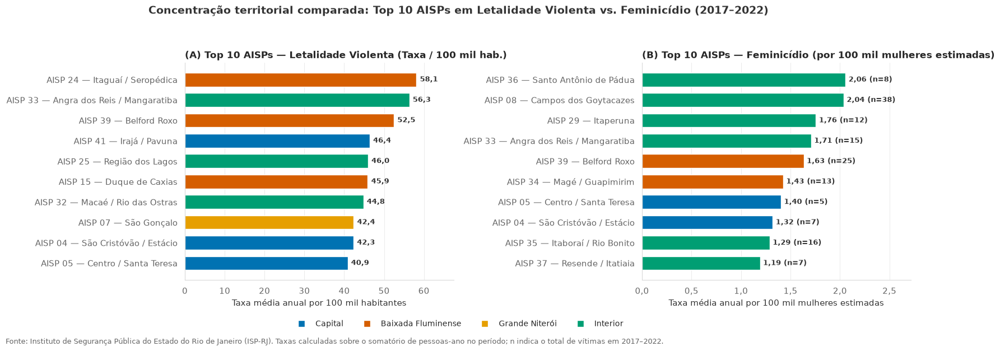

In [7]:
fig, (ax_b1, ax_b2) = plt.subplots(1, 2, figsize=(16.5, 6.2))

top10_let = comparativo_aisp_p1.nlargest(10, "taxa_media_letalidade").sort_values("taxa_media_letalidade")
cores_let = top10_let["regiao_predominante"].map(PALETA_REGIOES).fillna(PALETA["cinza_medio"])
ax_b1.barh(top10_let["rotulo_aisp"], top10_let["taxa_media_letalidade"], color=cores_let, height=0.68)
for y_pos, val in enumerate(top10_let["taxa_media_letalidade"]):
    ax_b1.text(
        val + top10_let["taxa_media_letalidade"].max() * 0.015,
        y_pos,
        formatar_numero(val, 1),
        va="center", fontsize=9, fontweight="bold", color=PALETA["cinza_escuro"],
    )
ax_b1.set_title("(A) Top 10 AISPs — Letalidade Violenta (Taxa / 100 mil hab.)", loc="left")
ax_b1.set_xlabel("Taxa média anual por 100 mil habitantes")
ax_b1.set_xlim(0, top10_let["taxa_media_letalidade"].max() * 1.16)
ax_b1.grid(axis="y", visible=False)

top10_fem = comparativo_aisp_p1.nlargest(10, "taxa_media_feminicidio").sort_values("taxa_media_feminicidio")
cores_fem = top10_fem["regiao_predominante"].map(PALETA_REGIOES).fillna(PALETA["cinza_medio"])
ax_b2.barh(top10_fem["rotulo_aisp"], top10_fem["taxa_media_feminicidio"], color=cores_fem, height=0.68)
for y_pos, (_, row) in enumerate(top10_fem.iterrows()):
    val = row["taxa_media_feminicidio"]
    n_casos = int(row["total_feminicidio"])
    ax_b2.text(
        val + top10_fem["taxa_media_feminicidio"].max() * 0.015,
        y_pos,
        f"{formatar_numero(val, 2)} (n={n_casos})",
        va="center", fontsize=9, fontweight="bold", color=PALETA["cinza_escuro"],
    )
ax_b2.set_title("(B) Top 10 AISPs — Feminicídio (por 100 mil mulheres estimadas)", loc="left")
ax_b2.set_xlabel("Taxa média anual por 100 mil mulheres estimadas")
ax_b2.set_xlim(0, top10_fem["taxa_media_feminicidio"].max() * 1.32)
ax_b2.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: formatar_numero(v, 1)))
ax_b2.grid(axis="y", visible=False)

handles_reg = [
    plt.Line2D([0], [0], marker="s", color="w", markerfacecolor=cor, markersize=9, label=reg)
    for reg, cor in PALETA_REGIOES.items()
]
fig.legend(handles=handles_reg, loc="lower center", ncol=4, bbox_to_anchor=(0.5, 0.03), frameon=False, fontsize=10)

fig.suptitle(
    f"Concentração territorial comparada: Top 10 AISPs em Letalidade Violenta vs. Feminicídio ({ano_inicio_fem_completo}–{ultimo_ano_pop})",
    fontsize=13.5, fontweight="bold", y=0.98, color=PALETA["cinza_escuro"],
)
fig.text(
    0.01, 0.005,
    f"{FONTE_PADRAO} Taxas calculadas sobre o somatório de pessoas-ano no período; n indica o total de vítimas em 2017–2022.",
    fontsize=9, color=PALETA["cinza_medio"],
)
plt.tight_layout(rect=[0, 0.08, 1, 0.94])
plt.show()

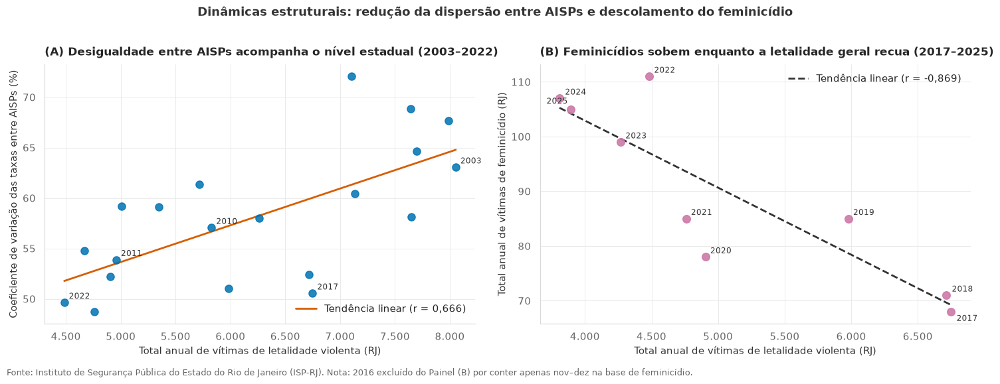

In [8]:
cv_letalidade = (
    resumo_estatistico[["ano", "coef_variacao"]]
    .merge(letalidade_anual, on="ano", validate="one_to_one")
    .query("2003 <= ano <= 2022")
    .sort_values("ano")
)
r_cv = cv_letalidade["coef_variacao"].corr(cv_letalidade["quantidade_letalidade_violenta"])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.4))

x1 = cv_letalidade["quantidade_letalidade_violenta"]
y1 = cv_letalidade["coef_variacao"]
a1, b1 = np.polyfit(x1, y1, 1)
ax1.scatter(x1, y1, color=PALETA["azul"], s=65, alpha=0.85, zorder=3)
ax1.plot(
    np.sort(x1), a1 * np.sort(x1) + b1, color=PALETA["vermelho"], lw=2,
    label=f"Tendência linear (r = {formatar_numero(r_cv, 3)})",
)
for _, row in cv_letalidade.iterrows():
    if int(row["ano"]) in {2003, 2010, 2011, 2017, 2022}:
        ax1.annotate(
            str(int(row["ano"])),
            (row["quantidade_letalidade_violenta"], row["coef_variacao"]),
            xytext=(5, 4), textcoords="offset points", fontsize=8.5, color=PALETA["cinza_escuro"],
        )
ax1.set_title("(A) Desigualdade entre AISPs acompanha o nível estadual (2003–2022)", loc="left", pad=10)
ax1.set_xlabel("Total anual de vítimas de letalidade violenta (RJ)")
ax1.set_ylabel("Coeficiente de variação das taxas entre AISPs (%)")
ax1.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: formatar_numero(v, 0)))
ax1.legend(loc="lower right")

x2 = serie_let_fem_uf["quantidade_letalidade_violenta"]
y2 = serie_let_fem_uf["quantidade_morte_feminicidio"]
a2, b2 = np.polyfit(x2, y2, 1)
ax2.scatter(x2, y2, color=PALETA["roxo"], s=70, alpha=0.9, zorder=3)
ax2.plot(
    np.sort(x2), a2 * np.sort(x2) + b2, color=PALETA["cinza_escuro"], lw=2, linestyle="--",
    label=f"Tendência linear (r = {formatar_numero(r_temporal_let_fem_2017_2025, 3)})",
)
deslocamentos_p1 = {
    2017: (6, -10),
    2018: (6, 4),
    2024: (6, 4),
    2025: (-26, 6),
}
for _, row in serie_let_fem_uf.iterrows():
    ano_int = int(row["ano"])
    dx_p1, dy_p1 = deslocamentos_p1.get(ano_int, (5, 4))
    ax2.annotate(
        str(ano_int),
        (row["quantidade_letalidade_violenta"], row["quantidade_morte_feminicidio"]),
        xytext=(dx_p1, dy_p1), textcoords="offset points", fontsize=8.5, color=PALETA["cinza_escuro"],
    )
ax2.set_title("(B) Feminicídios sobem enquanto a letalidade geral recua (2017–2025)", loc="left", pad=10)
ax2.set_xlabel("Total anual de vítimas de letalidade violenta (RJ)")
ax2.set_ylabel("Total anual de vítimas de feminicídio (RJ)")
ax2.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: formatar_numero(v, 0)))
ax2.legend(loc="upper right")

fig.suptitle(
    "Dinâmicas estruturais: redução da dispersão entre AISPs e descolamento do feminicídio",
    fontsize=13, fontweight="bold", y=1.01, color=PALETA["cinza_escuro"],
)
fig.text(
    0.01, -0.02,
    f"{FONTE_PADRAO} Nota: 2016 excluído do Painel (B) por conter apenas nov–dez na base de feminicídio.",
    fontsize=9, color=PALETA["cinza_medio"],
)
plt.tight_layout()
plt.show()

### Leitura Analítica

1. **Risco proporcional vs. volume absoluto (2017–2022):** a normalização populacional reordena o mapa de risco. Embora áreas muito populosas como **AISP 07 — São Gonçalo** (2.746 vítimas; 42,37/100 mil, 8º lugar) e **AISP 15 — Duque de Caxias** (2.525 vítimas; 45,91/100 mil, 6º lugar) concentrem os maiores totais brutos, as taxas mais altas ocorrem em **AISP 24 — Itaguaí / Seropédica** (**58,13**/100 mil), **AISP 33 — Angra dos Reis / Mangaratiba** (**56,34**/100 mil) e **AISP 39 — Belford Roxo** (**52,48**/100 mil).
2. **Queda estadual e menor dispersão territorial (2003–2022):** o total estadual caiu de **8.054** para **4.485 vítimas** (**−3.569 vítimas**, redução de **44,3%**), enquanto o coeficiente de variação das taxas entre AISPs recuou de **63,1%** para **49,7%**, acompanhando positivamente o volume estadual ($r = 0{,}666$).
3. **Geografia própria e descolamento do feminicídio:** a correlação espacial entre as duas taxas por AISP é baixa ($r = 0{,}354$). Enquanto a letalidade geral se concentra na Região Metropolitana e no litoral, **6 das 10 maiores taxas de feminicídio estão no Interior**, lideradas por **AISP 36 — Santo Antônio de Pádua** (**2,06**/100 mil mulheres; $n = 8$), **AISP 08 — Campos dos Goytacazes** (**2,04**; $n = 38$) e **AISP 29 — Itaperuna** (**1,76**; $n = 12$) — com cautela para diferenças decimais em territórios menos populosos. No agregado estadual (2017–2025), os fenômenos divergem fortemente ($r = -0{,}869$): a letalidade geral caiu de 6.749 para 3.892 casos, enquanto os feminicídios passaram de **68** (2017) para **111** (2022, alta de **+63,2%**) e **105** (2025). Uma hipótese central é que áreas do **Interior** e de parte da **Região Metropolitana** que antes não classificavam casos como feminicídio passaram a registrá-los com o amadurecimento institucional da Lei nº 13.104/2015, reforçando a dinâmica interpessoal/doméstica distinta da letalidade geral.

## 4. Convergência regional e interiorização relativa da letalidade (1991–2022)

> **Pergunta de domínio 2:** *Como se compara a evolução temporal da taxa de letalidade entre a capital (Rio de Janeiro), a Região Metropolitana e as regiões do interior?*

Passando da geografia por AISP para a trajetória de longo prazo por região, utilizamos `df_letalidade` (`delito == "Letalidade Violenta"`). A série de `Capital` e `Estado` remonta a **1991**, enquanto as quatro regiões completas permitem comparação contínua a partir de **2000**. Preservamos o horizonte longo (`1991–2022`) no gráfico interativo de trajetórias, acompanhamos a dispersão (coeficiente de variação) e a participação regional das ocorrências em toda a janela comum **`2000–2022`**, e adotamos **`2003–2022`** (alinhada ao recorte das demais seções do artigo) para mensurar a variação acumulada e a razão Máx/Mín.

In [9]:
exigir_colunas(
    df_letalidade,
    ["ano", "regiao", "delito", "contagem_delito", "populacao", "taxa_cem_mil_habitantes"],
    "df_letalidade",
)

quatro_reg = ["Capital", "Baixada Fluminense", "Grande Niterói", "Interior"]

def normalizar_regiao(valor: object) -> str:
    '''Normaliza o nome de uma região removendo acentos e padronizando caixa.

    Args:
        valor: Texto ou valor representando o nome da região na base de dados.

    Returns:
        String normalizada em minúsculas, sem acentuação e sem espaços extras.
    '''
    texto = unicodedata.normalize("NFKD", str(valor))
    return "".join(ch for ch in texto if not unicodedata.combining(ch)).casefold().strip()

canonico_p2 = {normalizar_regiao(r): r for r in [*quatro_reg, "Estado"]}
df_letalidade_p2 = df_letalidade.copy()
df_letalidade_p2["regiao_p2"] = df_letalidade_p2["regiao"].map(
    lambda valor: canonico_p2.get(normalizar_regiao(valor))
)
cols_resumo_p2 = [*quatro_reg, "Estado"]

df_let_p2 = (
    df_letalidade_p2.loc[
        (df_letalidade_p2["delito"] == "Letalidade Violenta")
        & (df_letalidade_p2["regiao_p2"].isin(cols_resumo_p2))
    ]
    .assign(regiao=lambda base: base["regiao_p2"])
    .sort_values(["regiao", "ano"])
    .copy()
)

piv_p2 = (
    df_let_p2.pivot(index="ano", columns="regiao", values="taxa_cem_mil_habitantes")
    .sort_index()
)

anos_comuns_p2 = piv_p2[quatro_reg].dropna().index
ano_ini_comum_p2, ano_fim_comum_p2 = int(anos_comuns_p2.min()), int(anos_comuns_p2.max())

anos_marco = [1991, 1995, 2003, 2008, 2012, 2017, 2020, 2022]
resumo_p2_marcos = piv_p2.loc[piv_p2.index.isin(anos_marco), cols_resumo_p2].round(2)

resumo_p2_extremos = pd.DataFrame({
    "taxa_2003": piv_p2.loc[2003, cols_resumo_p2],
    "ano_pico": piv_p2[cols_resumo_p2].idxmax(),
    "taxa_pico": piv_p2[cols_resumo_p2].max(),
    "ano_vale": piv_p2[cols_resumo_p2].idxmin(),
    "taxa_vale": piv_p2[cols_resumo_p2].min(),
    "taxa_2022": piv_p2.loc[2022, cols_resumo_p2],
    "var_2003_2022_pct": ((piv_p2.loc[2022, cols_resumo_p2] / piv_p2.loc[2003, cols_resumo_p2]) - 1) * 100,
}).round(2)

piv_comum = piv_p2.loc[anos_comuns_p2, quatro_reg]
media_regional_p2 = piv_comum.mean(axis=1)
desvio_regional_p2 = piv_comum.std(axis=1, ddof=0)
cv_regioes_p2 = (
    desvio_regional_p2.div(media_regional_p2.where(media_regional_p2.ne(0)))
    .mul(100)
    .rename("coef_variacao")
    .reset_index()
)
razao_max_min_p2 = piv_comum.max(axis=1).div(piv_comum.min(axis=1))

df_let_p2["contagem_p2"] = (
    df_let_p2["taxa_cem_mil_habitantes"].mul(df_let_p2["populacao"])
    .div(FATOR_TAXA)
    .round()
)

contagens_regioes_p2 = (
    df_let_p2.loc[df_let_p2["regiao"].isin(quatro_reg)]
    .pivot(index="ano", columns="regiao", values="contagem_p2")
    .reindex(index=anos_comuns_p2, columns=quatro_reg)
)
if contagens_regioes_p2.isna().any().any():
    raise ValueError("Há contagens ausentes para uma das quatro regiões.")
totais_regionais_p2 = contagens_regioes_p2.sum(axis=1)
if totais_regionais_p2.le(0).any():
    raise ValueError("Há total regional nulo ou negativo.")
proporcoes_p2 = contagens_regioes_p2.div(totais_regionais_p2, axis=0).mul(100)
if not np.allclose(proporcoes_p2.sum(axis=1), 100):
    raise ValueError("As participações regionais não somam 100% em todos os anos.")
proporcao_regional_p2 = (
    proporcoes_p2.rename_axis("ano")
    .reset_index()
    .melt(id_vars="ano", var_name="regiao", value_name="proporcao_percentual")
)
display(resumo_p2_extremos)


,taxa_2003,ano_pico,taxa_pico,ano_vale,taxa_vale,taxa_2022,var_2003_2022_pct
regiao,,,,,,,
Capital,58.3,1994,75.9,2021,19.3,19.4,-66.72
Baixada Fluminense,70.4,2003,70.4,2021,35.6,35.9,-49.01
Grande Niterói,52.2,2002,66.8,2022,24.7,24.7,-52.68
Interior,34.5,2005,38.3,2011,23.7,26.0,-24.64
Estado,54.3,1994,64.8,2022,25.5,25.5,-53.04


In [10]:
ordem_plot_p2 = ["Baixada Fluminense", "Capital", "Grande Niterói", "Interior", "Estado"]
df_plot_p2 = df_let_p2.loc[df_let_p2["regiao"].isin(ordem_plot_p2)].copy()

cores_p2 = {**PALETA_REGIOES, "Estado": PALETA["cinza_escuro"]}

fig_p2 = px.line(
    df_plot_p2,
    x="ano",
    y="taxa_cem_mil_habitantes",
    color="regiao",
    category_orders={"regiao": ordem_plot_p2},
    color_discrete_map=cores_p2,
    markers=False,
    labels={
        "ano": "Ano",
        "taxa_cem_mil_habitantes": "Taxa de Letalidade Violenta / 100 mil hab.",
        "regiao": "Região",
    },
    title=(
        "<b>Evolução Histórica da Taxa de Letalidade Violenta por Região do RJ (1991–2022)</b>"
        "<br><sup>Vítimas por 100 mil habitantes — Capital, Entorno Metropolitano (Baixada e Grande Niterói) e Interior</sup>"
    ),
)

fig_p2.update_traces(line=dict(width=2.5))
fig_p2.update_traces(
    line=dict(width=2.4, dash="dash"),
    selector=dict(name="Estado"),
)

marcos_verticais = [
    (2008, "Início UPPs (2008)", 1.03),
    (2014, "Copa (2014)", 0.90),
    (2016, "Olimpíadas / Crise fiscal (2016)", 0.97),
    (2020, "Pandemia / ADPF 635 (2020)", 1.03),
]
for ano_m, rotulo_m, y_pos in marcos_verticais:
    fig_p2.add_vline(x=ano_m, line_width=1, line_dash="dot", line_color=PALETA["cinza_medio"], opacity=0.65)
    fig_p2.add_annotation(
        x=ano_m, y=y_pos, yref="paper", text=rotulo_m,
        showarrow=False, font=dict(size=10, color=PALETA["cinza_medio"]),
        xanchor="left", xshift=4,
    )

fig_p2.update_layout(
    height=540,
    hovermode="x unified",
    legend=dict(orientation="h", yanchor="bottom", y=-0.20, xanchor="center", x=0.5),
    margin=dict(l=50, r=30, t=95, b=105),
    xaxis=dict(dtick=2),
)
adicionar_fonte_plotly(fig_p2, y=-0.27)
fig_p2.show()

In [11]:
ordem_reg_p2 = [
    "Capital",
    "Baixada Fluminense",
    "Grande Niterói",
    "Interior",
]

anos_animacao_p2 = sorted(proporcao_regional_p2["ano"].unique())

participacoes_por_ano_p2 = {
    ano: (
        proporcao_regional_p2.loc[
            proporcao_regional_p2["ano"].eq(ano)
        ]
        .set_index("regiao")
        .reindex(ordem_reg_p2)["proporcao_percentual"]
    )
    for ano in anos_animacao_p2
}

maior_participacao_p2 = proporcao_regional_p2["proporcao_percentual"].max()
limite_superior_p2 = min(100, maior_participacao_p2 * 1.15)

fig_p2_cv = go.Figure(
    data=[
        go.Scatter(
            x=cv_regioes_p2["ano"],
            y=cv_regioes_p2["coef_variacao"],
            mode="lines+markers",
            line=dict(color=PALETA["azul"], width=2.5),
            marker=dict(size=6, color=PALETA["azul"]),
            name="Coeficiente de variação",
            showlegend=False,
            hovertemplate="Ano: %{x}<br>CV: %{y:.1f}%<extra></extra>",
        )
    ]
)

fig_p2_cv.update_layout(
    title=dict(
        text="<b>Coeficiente de Variação das Taxas de Letalidade entre Regiões (2000–2022)</b>",
        x=0.02,
        xanchor="left",
    ),
    height=420,
    paper_bgcolor="white",
    plot_bgcolor="white",
    font=dict(color=PALETA["cinza_escuro"]),
    margin=dict(l=60, r=35, t=75, b=85),
    hovermode="x unified",
)
fig_p2_cv.update_xaxes(
    title_text="Ano",
    dtick=2,
    showline=True,
    linecolor="#D9D9D9",
    tickfont=dict(color=PALETA["cinza_medio"]),
)
fig_p2_cv.update_yaxes(
    title_text="Coeficiente de variação (%)",
    showgrid=True,
    gridcolor="#EAEAEA",
    zeroline=False,
)
adicionar_fonte_plotly(fig_p2_cv, y=-0.24)
fig_p2_cv.show()

ano_inicial_p2 = anos_animacao_p2[0]

fig_p2_part = go.Figure(
    data=[
        go.Bar(
            x=ordem_reg_p2,
            y=participacoes_por_ano_p2[ano_inicial_p2].to_numpy(),
            marker_color=[PALETA_REGIOES[regiao] for regiao in ordem_reg_p2],
            width=0.45,
            name="Participação",
            showlegend=False,
            hovertemplate="%{x}<br>Participação: %{y:.1f}%<extra></extra>",
        )
    ],
    frames=[
        go.Frame(
            name=str(ano),
            data=[
                go.Bar(
                    x=ordem_reg_p2,
                    y=participacoes_por_ano_p2[ano].to_numpy(),
                    marker_color=[PALETA_REGIOES[regiao] for regiao in ordem_reg_p2],
                    width=0.45,
                    hovertemplate="%{x}<br>Participação: %{y:.1f}%<extra></extra>",
                )
            ],
        )
        for ano in anos_animacao_p2
    ],
)

passos_ano_p2 = [
    dict(
        method="animate",
        args=[
            [str(ano)],
            dict(
                mode="immediate",
                frame=dict(duration=0, redraw=True),
                transition=dict(duration=0),
            ),
        ],
        label=str(ano),
    )
    for ano in anos_animacao_p2
]

fig_p2_part.update_layout(
    title=dict(
        text="<b>Participação Regional nas Ocorrências de Letalidade Violenta (2000–2022)</b>",
        x=0.02,
        xanchor="left",
    ),
    height=520,
    paper_bgcolor="white",
    plot_bgcolor="white",
    font=dict(color=PALETA["cinza_escuro"]),
    margin=dict(l=60, r=35, t=95, b=175),
    bargap=0.40,
    hovermode="closest",
    sliders=[
        dict(
            active=0,
            currentvalue=dict(prefix="Ano: "),
            pad=dict(t=8),
            y=-0.16,
            steps=passos_ano_p2,
        )
    ],
    updatemenus=[
        dict(
            type="buttons",
            direction="left",
            x=0.98,
            y=1.18,
            xanchor="right",
            yanchor="top",
            buttons=[
                dict(
                    label="Reproduzir",
                    method="animate",
                    args=[
                        None,
                        dict(
                            fromcurrent=True,
                            frame=dict(duration=500, redraw=True),
                            transition=dict(duration=250),
                        ),
                    ],
                ),
                dict(
                    label="Pausar",
                    method="animate",
                    args=[
                        [None],
                        dict(
                            mode="immediate",
                            frame=dict(duration=0, redraw=False),
                            transition=dict(duration=0),
                        ),
                    ],
                ),
            ],
        )
    ],
)
fig_p2_part.update_xaxes(
    title_text=None,
    showline=True,
    linecolor="#D9D9D9",
    tickfont=dict(color=PALETA["cinza_medio"]),
)
fig_p2_part.update_yaxes(
    title_text="Participação no total (%)",
    range=[0, limite_superior_p2],
    ticksuffix="%",
    showgrid=True,
    gridcolor="#EAEAEA",
    zeroline=False,
)
adicionar_fonte_plotly(fig_p2_part, y=-0.52)
fig_p2_part.show()

### Leitura Analítica

- **Forte retração metropolitana:** entre 1991 e 2022, a taxa da **Capital** caiu **−70,3%** (de 65,2, após pico de 75,9 em 1994, para **19,4**/100 mil hab.). Na janela comparativa **2003–2022**, a queda foi de **−66,7%** na Capital (58,3 → 19,4), **−52,7%** em **Grande Niterói** (52,2 → 24,7) e **−49,0%** na **Baixada Fluminense** (70,4 → 35,9), que ainda permanece no topo do risco regional.
- **Rigidez no Interior e inversão histórica:** o **Interior** registrou recuo bem mais modesto no período (**−24,6%**, de 34,5 para **26,0**/100 mil). Como resultado, houve **inversão histórica**: em 2022, Interior (26,0) e Grande Niterói (24,7) encerraram a série com taxas superiores à da Capital (19,4).
- **Convergência sob choques comuns:** a razão entre a maior e a menor taxa regional estreitou-se de **2,04×** (2003) para **1,85×** (2022), acompanhada pela redistribuição da participação relativa das ocorrências em favor do Interior e da Baixada Fluminense. Já o coeficiente de variação regional **não recuou de forma monotônica**: na janela 2000–2022, subiu **+2,8 p.p.**, partindo de **19,7%** (2000), atingindo pico de **36,5%** em **2014** — período de retração da participação da Capital e ganho relativo do Interior e da Baixada Fluminense — e retornando a **22,5%** em 2022 (queda líquida apenas frente a 2003, de **24,0%**). Como hipóteses para essa mudança regional, destacam-se a implantação das **UPPs** desde 2008 (mais concentrada na Capital) e o contexto da **Copa do Mundo de 2014** e dos **Jogos Olímpicos de 2016**. Ainda assim, todas as regiões oscilam em sincronia diante de choques estaduais — queda em 2008–2012, repique na crise fiscal de 2016–2017 e novo recuo em 2019–2022.

## 5. O calendário da violência: sazonalidade sincronizada entre regiões

> **Pergunta de domínio 3:** *Como se comporta a sazonalidade da letalidade violenta ao longo dos meses do ano nas diferentes regiões de policiamento do estado?*

Além das diferenças espaciais e da trajetória de longo prazo, a violência letal varia de forma sistemática ao longo do ano. Agregamos `df_cisp_mensal` nos anos completos de **2003 a 2024** por região de policiamento (`Capital`, `Baixada Fluminense`, `Grande Niterói`, `Interior`) e no total estadual. Como fevereiro tem em média 28,25 dias (cerca de 9% menos que meses de 31 dias), convertemos cada soma mensal em **intensidade diária média** e construímos um **Índice Sazonal (Base 100 = média diária anual da região)**.

In [12]:
exigir_colunas(df_cisp_mensal, ["ano", "mes", "regiao", "quantidade_letalidade_violenta"], "df_cisp_mensal")

regioes_ordem_p3 = ["Capital", "Baixada Fluminense", "Grande Niterói", "Interior"]
meses_rotulos = ["Jan", "Fev", "Mar", "Abr", "Mai", "Jun", "Jul", "Ago", "Set", "Out", "Nov", "Dez"]
base_p3 = df_cisp_mensal.loc[
    df_cisp_mensal["ano"].between(2003, 2024)
    & df_cisp_mensal["regiao"].isin(regioes_ordem_p3)
].copy()

anos_meses_p3 = base_p3[["ano", "mes"]].drop_duplicates().copy()
anos_meses_p3["dias_mes"] = pd.to_datetime(
    {"year": anos_meses_p3["ano"], "month": anos_meses_p3["mes"], "day": 1}
).dt.days_in_month
dias_por_mes = (
    anos_meses_p3.groupby("mes")["dias_mes"]
    .mean()
    .reindex(range(1, 13))
)

sazonal_reg = (
    base_p3.groupby(["regiao", "mes"])["quantidade_letalidade_violenta"]
    .sum()
    .unstack("mes")
    .reindex(index=regioes_ordem_p3, columns=range(1, 13))
)
sazonal_estado = (
    base_p3.groupby("mes")["quantidade_letalidade_violenta"]
    .sum()
    .reindex(range(1, 13))
    .rename("Estado (RJ)")
    .to_frame()
    .T
)
sazonal_bruto = pd.concat([sazonal_reg, sazonal_estado], axis=0)

intensidade_diaria = sazonal_bruto.div(dias_por_mes, axis=1)
indice_sazonal = intensidade_diaria.div(intensidade_diaria.mean(axis=1), axis=0).mul(100)
indice_sazonal.columns = meses_rotulos

resumo_p3 = pd.DataFrame({
    "mes_pico": indice_sazonal.idxmax(axis=1),
    "indice_pico": indice_sazonal.max(axis=1).round(2),
    "mes_vale": indice_sazonal.idxmin(axis=1),
    "indice_vale": indice_sazonal.min(axis=1).round(2),
    "amplitude_pts": (indice_sazonal.max(axis=1) - indice_sazonal.min(axis=1)).round(2),
})

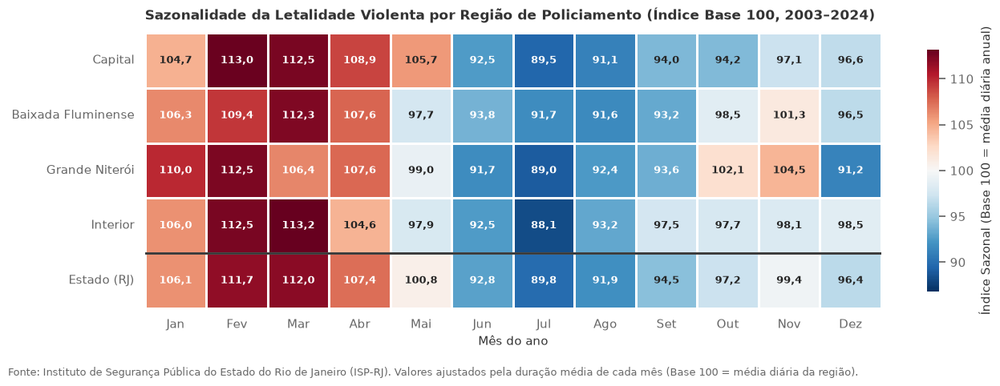

In [13]:
fig, ax = plt.subplots(figsize=(13.5, 4.8))

desvio_max = max(abs(indice_sazonal.values.max() - 100), abs(100 - indice_sazonal.values.min()))
vmin, vmax = 100 - desvio_max, 100 + desvio_max

sns.heatmap(
    indice_sazonal,
    ax=ax,
    cmap="RdBu_r",
    center=100,
    vmin=vmin,
    vmax=vmax,
    annot=indice_sazonal.map(lambda v: formatar_numero(v, 1)),
    fmt="",
    linewidths=0.8,
    linecolor="white",
    cbar_kws={"label": "Índice Sazonal (Base 100 = média diária anual)", "shrink": 0.88},
    annot_kws={"fontsize": 9.5, "fontweight": "bold"},
)

ax.axhline(4, color=PALETA["cinza_escuro"], lw=2.0)
ax.set_title(
    "Sazonalidade da Letalidade Violenta por Região de Policiamento (Índice Base 100, 2003–2024)",
    loc="left", pad=12, fontsize=12.5, fontweight="bold", color=PALETA["cinza_escuro"],
)
ax.set_xlabel("Mês do ano")
ax.set_ylabel("")
ax.tick_params(axis="y", rotation=0)

fig.text(
    0.01, 0.005,
    f"{FONTE_PADRAO} Valores ajustados pela duração média de cada mês (Base 100 = média diária da região).",
    fontsize=9, color=PALETA["cinza_medio"],
)
plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.show()

In [14]:
df_saz_long = (
    indice_sazonal.reset_index()
    .rename(columns={"index": "regiao"})
    .melt(id_vars="regiao", var_name="mes", value_name="indice_sazonal")
)
df_saz_long["mes"] = pd.Categorical(df_saz_long["mes"], categories=meses_rotulos, ordered=True)

cores_p3 = {**PALETA_REGIOES, "Estado (RJ)": PALETA["cinza_escuro"]}

fig_p3 = px.line(
    df_saz_long,
    x="mes",
    y="indice_sazonal",
    color="regiao",
    markers=True,
    color_discrete_map=cores_p3,
    labels={"mes": "Mês", "indice_sazonal": "Índice Sazonal (Base 100)", "regiao": "Região"},
    title=(
        "<b>Ciclo Sazonal da Letalidade Violenta nas Regiões do RJ (2003–2024)</b>"
        "<br><sup>Índice Base 100 ajustado por dias/mês — clique na legenda para filtrar regiões</sup>"
    ),
)

fig_p3.add_hline(
    y=100, line_dash="dot", line_color=PALETA["cinza_medio"],
    annotation_text="Média anual (100)", annotation_position="top right",
)
fig_p3.update_traces(line=dict(width=2.3), marker=dict(size=6))
fig_p3.update_traces(
    line=dict(width=3.0, dash="dash"),
    selector=dict(name="Estado (RJ)"),
)
fig_p3.update_layout(
    height=480,
    hovermode="x unified",
    legend=dict(orientation="h", yanchor="bottom", y=1.02, xanchor="left", x=0),
    margin=dict(l=40, r=30, t=95, b=65),
)
adicionar_fonte_plotly(fig_p3, y=-0.16)
fig_p3.show()

### Leitura Analítica

- **Regime sazonal comum em todo o estado:** controlado o efeito calendário, o Rio de Janeiro exibe um ciclo anual nítido, com maior intensidade diária no primeiro quadrimestre (`Jan–Abr`) — pico em **março** (**111,97**) e **fevereiro** (**111,7**) — e vale nos meses de inverno (**julho**, **89,81**), perfazendo amplitude de **22,16 pontos**.
- **Contraste regional de amplitude:** o **Interior** apresenta a oscilação sazonal mais acentuada (**25,06 pontos**, de **88,15** em julho a **113,21** em março), seguido por **Capital** (**23,53 pontos**, pico em fevereiro de **113,01** e vale de **89,48** em julho) e **Grande Niterói** (**23,42 pontos**, pico em fevereiro de **112,45** e vale de **89,04** em julho). Já a **Baixada Fluminense** mantém o patamar mais persistente ao longo do ano, com a menor amplitude (**20,73 pontos**).
- **Relevância do ajuste por dias do mês e limite interpretativo:** sem normalizar pela duração exata dos meses (considerando os 6 anos bissextos de 2003–2024), fevereiro pareceria artificialmente mais brando; o ajuste mostra que ele é o mês de maior risco diário na Capital e em Grande Niterói. O grupo identificou esse padrão recorrente na visualização **sem estabelecer uma hipótese conclusiva para explicar sua causa**; ressalva-se ainda que a soma acumulada pondera proporcionalmente mais os anos de maior volume histórico (década de 2000).


## 6. Menos armas, maior poder de fogo: a escalada dos fuzis (2007–2024)

> **Pergunta de domínio 4:** *Qual é a evolução histórica do volume absoluto e da taxa (por 100 mil habitantes) de armas de fogo e fuzis apreendidos no estado do Rio de Janeiro nos últimos anos?*

Encerrando o diagnóstico estadual, voltamos ao instrumento central dos confrontos armados. A partir de `armas_apreendidas_mensal`, agregamos anualmente os volumes completos de **2007 a 2024** (total de armas, fuzis, pistolas e revólveres) e os normalizamos pela população estadual (`populacao_uf_anual`). Como a série populacional estadual de `df_letalidade` encerra-se em 2022, adotamos propagação (*forward fill*, `ffill`) para 2023 e 2024 sob hipótese de estabilidade demográfica no biênio. Para comparar trajetórias de grandezas muito distintas sem distorção de eixos duplos, construímos um **Índice Base 100 (2007 = 100)** das taxas e a **composição percentual** do arsenal.

In [15]:
colunas_armas_p4 = [
    "quantidade_arma_fogo_total",
    "quantidade_fuzil",
    "quantidade_pistola",
    "quantidade_revolver",
]
exigir_colunas(df_armas, ["ano", *colunas_armas_p4], "df_armas")

armas_anual = (
    df_armas.loc[df_armas["ano"].between(2007, 2024)]
    .groupby("ano", as_index=False)[colunas_armas_p4]
    .sum()
    .sort_values("ano")
    .merge(populacao_uf_anual, on="ano", how="left", validate="one_to_one")
)

anos_pop_ausente = armas_anual.loc[armas_anual["populacao"].isna(), "ano"].tolist()
if anos_pop_ausente:
    armas_anual["populacao"] = armas_anual["populacao"].ffill()

armas_anual["taxa_armas_populacao"] = taxa_por_100_mil(
    armas_anual["quantidade_arma_fogo_total"], armas_anual["populacao"]
)
armas_anual["taxa_fuzil_populacao"] = taxa_por_100_mil(
    armas_anual["quantidade_fuzil"], armas_anual["populacao"]
)

base_armas_2007 = armas_anual.loc[armas_anual["ano"] == 2007, "taxa_armas_populacao"].iloc[0]
base_fuzil_2007 = armas_anual.loc[armas_anual["ano"] == 2007, "taxa_fuzil_populacao"].iloc[0]
armas_anual["indice_taxa_armas"] = (armas_anual["taxa_armas_populacao"] / base_armas_2007) * 100
armas_anual["indice_taxa_fuzil"] = (armas_anual["taxa_fuzil_populacao"] / base_fuzil_2007) * 100

armas_anual["prop_revolver_por_total"] = (
    armas_anual["quantidade_revolver"] / armas_anual["quantidade_arma_fogo_total"]
) * 100
armas_anual["prop_pistola_por_total"] = (
    armas_anual["quantidade_pistola"] / armas_anual["quantidade_arma_fogo_total"]
) * 100
armas_anual["prop_fuzil_por_total"] = (
    armas_anual["quantidade_fuzil"] / armas_anual["quantidade_arma_fogo_total"]
) * 100

resumo_p4 = armas_anual[[
    "ano",
    "quantidade_arma_fogo_total",
    "taxa_armas_populacao",
    "quantidade_fuzil",
    "taxa_fuzil_populacao",
    "prop_revolver_por_total",
    "prop_pistola_por_total",
    "prop_fuzil_por_total",
]].round(2)

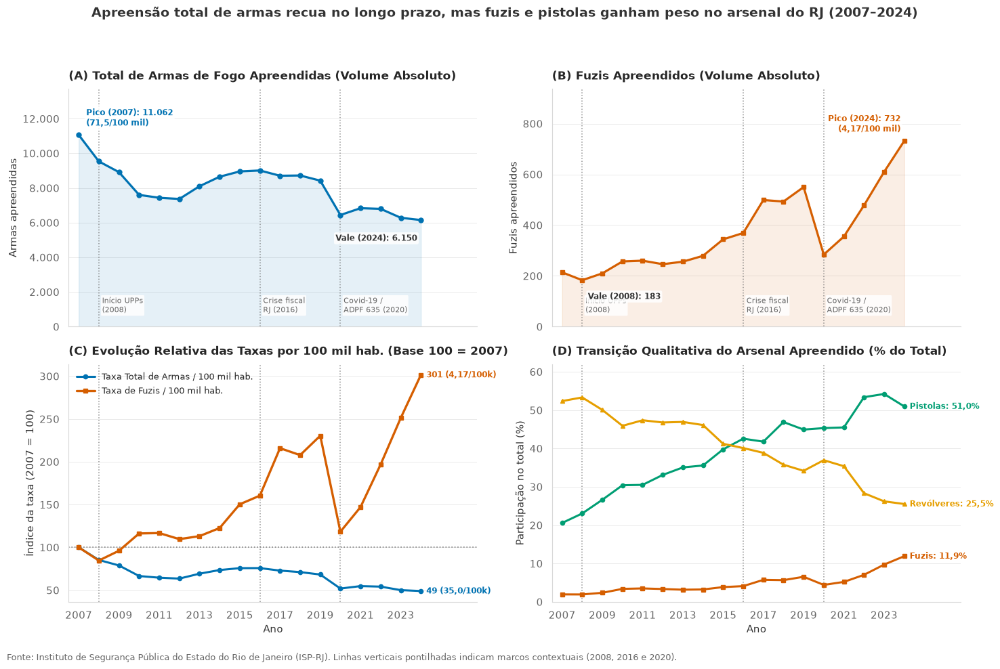

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9.8), sharex=True)
(ax_a, ax_b), (ax_c, ax_d) = axes
anos = armas_anual["ano"]

marcos_p4 = [
    (2008, "Início UPPs\n(2008)"),
    (2016, "Crise fiscal\nRJ (2016)"),
    (2020, "Covid-19 /\nADPF 635 (2020)"),
]


def anotar_ponto(
    ax: plt.Axes,
    df: pd.DataFrame,
    col_y: str,
    idx: int,
    texto: str,
    dy: float = 10,
    dx: float = 0,
    cor: str = PALETA["cinza_escuro"],
    ha: str = "center",
) -> None:
    '''Adiciona uma anotação destacada a um ponto específico de um gráfico Matplotlib.

    Args:
        ax: Eixo Matplotlib onde a anotação será inserida.
        df: DataFrame de origem contendo a coluna ``ano`` e ``col_y``.
        col_y: Nome da coluna correspondente à coordenada vertical.
        idx: Rótulo de índice da linha a ser anotada em ``df``.
        texto: Texto exibido na caixa de anotação.
        dy: Deslocamento vertical em pontos a partir do ponto de dados.
        dx: Deslocamento horizontal em pontos a partir do ponto de dados.
        cor: Cor hexadecimal ou nomeada aplicada ao texto da anotação.
        ha: Alinhamento horizontal do texto (``'left'``, ``'center'`` ou ``'right'``).

    Returns:
        None.
    '''
    x_val = df.loc[idx, "ano"]
    y_val = df.loc[idx, col_y]
    ax.annotate(
        texto,
        xy=(x_val, y_val),
        xytext=(dx, dy),
        textcoords="offset points",
        ha=ha,
        fontsize=8.5,
        fontweight="bold",
        color=cor,
        bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.85),
        zorder=5,
    )


def adicionar_marcos_historicos(
    ax: plt.Axes,
    marcos: list[tuple[int, str]],
    exibir_rotulos: bool = False,
    y_frac: float = 0.96,
    va: str = "top",
) -> None:
    '''Insere linhas verticais e rótulos opcionais de eventos históricos em um eixo.

    Args:
        ax: Eixo Matplotlib alvo.
        marcos: Lista de tuplas ``(ano, rotulo)`` descrevendo os acontecimentos.
        exibir_rotulos: Se ``True``, desenha o texto de cada marco junto à linha.
        y_frac: Posição vertical relativa do texto em coordenadas do eixo (0 a 1).
        va: Alinhamento vertical do texto (``'top'`` ou ``'bottom'``).

    Returns:
        None.
    '''
    for ano_marco, rotulo_marco in marcos:
        ax.axvline(
            ano_marco,
            color=PALETA["cinza_medio"],
            linestyle=":",
            linewidth=1.1,
            alpha=0.7,
            zorder=1,
        )
        if exibir_rotulos:
            ax.text(
                ano_marco + 0.16,
                y_frac,
                rotulo_marco,
                transform=ax.get_xaxis_transform(),
                fontsize=7.6,
                color=PALETA["cinza_medio"],
                va=va,
                ha="left",
                bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.85),
                zorder=4,
            )


ax_a.fill_between(anos, armas_anual["quantidade_arma_fogo_total"], color=PALETA["azul"], alpha=0.10)
ax_a.plot(anos, armas_anual["quantidade_arma_fogo_total"], marker="o", ms=5, lw=2.3, color=PALETA["azul"])
idx_max_a = armas_anual["quantidade_arma_fogo_total"].idxmax()
idx_min_a = armas_anual["quantidade_arma_fogo_total"].idxmin()
anotar_ponto(
    ax_a, armas_anual, "quantidade_arma_fogo_total", idx_max_a,
    (
        f"Pico ({int(armas_anual.loc[idx_max_a, 'ano'])}): "
        f"{formatar_numero(armas_anual.loc[idx_max_a, 'quantidade_arma_fogo_total'], 0)}\n"
        f"({formatar_numero(armas_anual.loc[idx_max_a, 'taxa_armas_populacao'], 1)}/100 mil)"
    ),
    dy=10, dx=8, cor=PALETA["azul"], ha="left",
)
anotar_ponto(
    ax_a, armas_anual, "quantidade_arma_fogo_total", idx_min_a,
    f"Vale ({int(armas_anual.loc[idx_min_a, 'ano'])}): {formatar_numero(armas_anual.loc[idx_min_a, 'quantidade_arma_fogo_total'], 0)}",
    dy=-22, dx=-4, cor=PALETA["cinza_escuro"], ha="right",
)
adicionar_marcos_historicos(ax_a, marcos_p4, exibir_rotulos=True, y_frac=0.05, va="bottom")
ax_a.set_title("(A) Total de Armas de Fogo Apreendidas (Volume Absoluto)", loc="left", pad=10)
ax_a.set_ylabel("Armas apreendidas")
ax_a.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: formatar_numero(v, 0)))
ax_a.set_ylim(0, armas_anual["quantidade_arma_fogo_total"].max() * 1.24)

ax_b.fill_between(anos, armas_anual["quantidade_fuzil"], color=PALETA["vermelho"], alpha=0.10)
ax_b.plot(anos, armas_anual["quantidade_fuzil"], marker="s", ms=5, lw=2.3, color=PALETA["vermelho"])
idx_max_b = armas_anual["quantidade_fuzil"].idxmax()
idx_min_b = armas_anual["quantidade_fuzil"].idxmin()
anotar_ponto(
    ax_b, armas_anual, "quantidade_fuzil", idx_max_b,
    (
        f"Pico ({int(armas_anual.loc[idx_max_b, 'ano'])}): {formatar_numero(armas_anual.loc[idx_max_b, 'quantidade_fuzil'], 0)}\n"
        f"({formatar_numero(armas_anual.loc[idx_max_b, 'taxa_fuzil_populacao'], 2)}/100 mil)"
    ),
    dy=10, dx=-4, cor=PALETA["vermelho"], ha="right",
)
anotar_ponto(
    ax_b, armas_anual, "quantidade_fuzil", idx_min_b,
    f"Vale ({int(armas_anual.loc[idx_min_b, 'ano'])}): {formatar_numero(armas_anual.loc[idx_min_b, 'quantidade_fuzil'], 0)}",
    dy=-20, dx=6, cor=PALETA["cinza_escuro"], ha="left",
)
adicionar_marcos_historicos(ax_b, marcos_p4, exibir_rotulos=True, y_frac=0.05, va="bottom")
ax_b.set_title("(B) Fuzis Apreendidos (Volume Absoluto)", loc="left", pad=10)
ax_b.set_ylabel("Fuzis apreendidos")
ax_b.set_ylim(0, armas_anual["quantidade_fuzil"].max() * 1.28)

ax_c.axhline(100, color=PALETA["cinza_medio"], linestyle=":", lw=1.2, alpha=0.8)
ax_c.plot(anos, armas_anual["indice_taxa_armas"], marker="o", ms=4.5, lw=2.2, color=PALETA["azul"], label="Taxa Total de Armas / 100 mil hab.")
ax_c.plot(anos, armas_anual["indice_taxa_fuzil"], marker="s", ms=4.5, lw=2.4, color=PALETA["vermelho"], label="Taxa de Fuzis / 100 mil hab.")
ult = armas_anual.index[-1]
ax_c.annotate(
    f"  {formatar_numero(armas_anual.loc[ult, 'indice_taxa_armas'], 0)} ({formatar_numero(armas_anual.loc[ult, 'taxa_armas_populacao'], 1)}/100k)",
    xy=(armas_anual.loc[ult, "ano"], armas_anual.loc[ult, "indice_taxa_armas"]),
    va="center", fontsize=8.5, fontweight="bold", color=PALETA["azul"],
)
ax_c.annotate(
    f"  {formatar_numero(armas_anual.loc[ult, 'indice_taxa_fuzil'], 0)} ({formatar_numero(armas_anual.loc[ult, 'taxa_fuzil_populacao'], 2)}/100k)",
    xy=(armas_anual.loc[ult, "ano"], armas_anual.loc[ult, "indice_taxa_fuzil"]),
    va="center", fontsize=8.5, fontweight="bold", color=PALETA["vermelho"],
)
adicionar_marcos_historicos(ax_c, marcos_p4, exibir_rotulos=False)
ax_c.set_title("(C) Evolução Relativa das Taxas por 100 mil hab. (Base 100 = 2007)", loc="left", pad=10)
ax_c.set_ylabel("Índice da taxa (2007 = 100)")
ax_c.set_xlabel("Ano")
ax_c.legend(loc="upper left", fontsize=9.5)

series_comp = [
    ("prop_pistola_por_total", "Pistolas", PALETA["verde"], "o"),
    ("prop_revolver_por_total", "Revólveres", PALETA["laranja"], "^"),
    ("prop_fuzil_por_total", "Fuzis", PALETA["vermelho"], "s"),
]
for col, rotulo, cor, marcador in series_comp:
    ax_d.plot(anos, armas_anual[col], marker=marcador, ms=4.5, lw=2.2, color=cor, label=rotulo)
    ax_d.annotate(
        f"  {rotulo}: {formatar_numero(armas_anual.loc[ult, col], 1)}%",
        xy=(armas_anual.loc[ult, "ano"], armas_anual.loc[ult, col]),
        va="center", fontsize=8.5, fontweight="bold", color=cor,
    )

adicionar_marcos_historicos(ax_d, marcos_p4, exibir_rotulos=False)
ax_d.set_title("(D) Transição Qualitativa do Arsenal Apreendido (% do Total)", loc="left", pad=10)
ax_d.set_ylabel("Participação no total (%)")
ax_d.set_xlabel("Ano")
ax_d.set_ylim(0, 62)

for ax in axes.flat:
    ax.set_xticks(range(2007, 2025, 2))
    ax.set_xlim(2006.5, 2026.8)
    ax.grid(axis="x", visible=False)

fig.suptitle(
    "Apreensão total de armas recua no longo prazo, mas fuzis e pistolas ganham peso no arsenal do RJ (2007–2024)",
    fontsize=13.5, fontweight="bold", y=0.99, color=PALETA["cinza_escuro"],
)
fig.text(
    0.01, 0.005,
    f"{FONTE_PADRAO} Linhas verticais pontilhadas indicam marcos contextuais (2008, 2016 e 2020).",
    fontsize=9, color=PALETA["cinza_medio"],
)
plt.tight_layout(rect=[0, 0.025, 1, 0.95])
plt.show()

### Leitura Analítica

A evidência do painel 2×2 revela uma **divergência estrutural entre quantidade total e poder de fogo**:

- **Recuo no volume total e na taxa populacional:** as apreensões totais caíram **44,4%**, de **11.062 armas** (71,47/100 mil hab.) em 2007 para **6.150** (35,02/100 mil) em 2024 — retração de **51,0%** na taxa proporcional, com repique intermediário durante a crise fiscal de 2016 (9.010) e queda brusca no início da pandemia de Covid-19 e da ADPF 635 em 2020 (6.440).
- **Triplicação dos fuzis:** na direção oposta, as apreensões de fuzis subiram **+242,1%** em volume (de **214** em 2007 — vale de 183 em 2008 — para o recorde de **732** em 2024) e **+201,5%** em taxa (1,38 → **4,17/100 mil hab.**), retomando aceleração forte após a quebra pontual de 2020 (284).
- **Substituição tecnológica do arsenal:** no Painel (D), os **revólveres** encolheram de **52,36%** (2007) para **25,51%** (2024), enquanto as **pistolas** saltaram de **20,57%** para **50,96%** (superando os revólveres em 2016) e os **fuzis** sextuplicaram sua fatia (1,93% → **11,90%**). Como a taxa de letalidade violenta caiu no mesmo período, o crescimento das apreensões de fuzis não indica necessariamente intensificação da criminalidade: a **hipótese do grupo** é que uma **atuação policial mais incisiva no combate ao crime organizado** (especialmente na Capital) pode ajudar a explicar, simultaneamente, a queda da letalidade e o salto nas apreensões de fuzis. Por se tratar de registros administrativos, as séries refletem conjuntamente a circulação ilícita de armamento e a focalização operacional das polícias.

## 7. Corredores de confronto: clusters de intervenção policial e armamento pesado

> **Pergunta de domínio 5:** *O mapeamento territorial revela agrupamentos (clusters) onde altas taxas de mortes por intervenção policial coexistem de forma consistente com volumes elevados de apreensão de armamento pesado?*

Conectando a escalada dos fuzis (Seção 6) ao mapa de letalidade (Seção 3), consolidamos o período **2017–2022** para as **39 AISPs** com cobertura populacional completa (entre os 41 polígonos da malha; AISPs 1 e 43 sem dados no período), cruzando o volume acumulado de fuzis apreendidos (`quantidade_fuzil`) com a taxa média anual de mortes por intervenção policial (`taxa_mdip_100k`). A classificação em **quatro quadrantes pelas medianas** separa o foco crítico (**Cluster 1: Alta MDIP + Alto Fuzil**) dos demais territórios, complementada por teste de robustez com a taxa proporcional de fuzis.

In [17]:
exigir_colunas(df_cisp_mensal, ["ano", "id_aisp", "quantidade_homicidio_intervencao_policial"], "df_cisp_mensal")
exigir_colunas(df_armas, ["ano", "id_aisp", "quantidade_fuzil"], "df_armas")

ano_ini_p5, ano_fim_p5 = 2017, int(populacao_por_ano_aisp["ano"].max())

mdip_aisp_ano = agregar_contagens_aisp_ano(
    df_cisp_mensal.loc[df_cisp_mensal["ano"].between(ano_ini_p5, ano_fim_p5)],
    ["quantidade_homicidio_intervencao_policial"],
)
fuzil_aisp_ano = agregar_contagens_aisp_ano(
    df_armas.loc[df_armas["ano"].between(ano_ini_p5, ano_fim_p5)],
    ["quantidade_fuzil"],
)

pop_p5 = (
    populacao_por_ano_aisp.loc[
        populacao_por_ano_aisp["ano"].between(ano_ini_p5, ano_fim_p5)
        & populacao_por_ano_aisp["meses_ativos"].eq(12)
    ]
    .groupby("id_aisp", as_index=False)
    .agg(pessoas_ano=("populacao", "sum"), pop_media=("populacao", "mean"))
)

painel_p5 = (
    pop_p5
    .merge(
        mdip_aisp_ano.groupby("id_aisp", as_index=False)["quantidade_homicidio_intervencao_policial"].sum(),
        on="id_aisp", how="left", validate="one_to_one",
    )
    .merge(
        fuzil_aisp_ano.groupby("id_aisp", as_index=False)["quantidade_fuzil"].sum(),
        on="id_aisp", how="left", validate="one_to_one",
    )
    .merge(
        dim_aisp[["id_aisp", "nome_aisp", "rotulo_aisp", "regiao_predominante"]],
        on="id_aisp", how="left", validate="one_to_one",
    )
)

painel_p5["quantidade_homicidio_intervencao_policial"] = painel_p5["quantidade_homicidio_intervencao_policial"].fillna(0)
painel_p5["quantidade_fuzil"] = painel_p5["quantidade_fuzil"].fillna(0)

painel_p5["taxa_mdip_100k"] = taxa_por_100_mil(
    painel_p5["quantidade_homicidio_intervencao_policial"], painel_p5["pessoas_ano"]
)
painel_p5["taxa_fuzil_populacao"] = taxa_por_100_mil(
    painel_p5["quantidade_fuzil"], painel_p5["pessoas_ano"]
)

mediana_fuzil = float(painel_p5["quantidade_fuzil"].median())
mediana_mdip = float(painel_p5["taxa_mdip_100k"].median())

def classificar_cluster(row: pd.Series) -> str:
    '''Classifica uma AISP em um dos quatro quadrantes de confronto armado.

    Compara o volume acumulado de fuzis apreendidos e a taxa média anual de
    mortes por intervenção policial (MDIP) com suas respectivas medianas.

    Args:
        row: Linha do painel territorial contendo ``quantidade_fuzil`` e
            ``taxa_mdip_100k``.

    Returns:
        Rótulo textual do cluster territorial correspondente (Cluster 1 a 4).
    '''
    alto_fuzil = row["quantidade_fuzil"] >= mediana_fuzil
    alta_mdip = row["taxa_mdip_100k"] >= mediana_mdip
    if alto_fuzil and alta_mdip:
        return "Cluster 1: Alta MDIP + Alto Fuzil"
    if (not alto_fuzil) and alta_mdip:
        return "Cluster 2: Alta MDIP + Baixo Fuzil"
    if alto_fuzil and (not alta_mdip):
        return "Cluster 3: Baixa MDIP + Alto Fuzil"
    return "Cluster 4: Baixa MDIP + Baixo Fuzil"

painel_p5["cluster"] = painel_p5.apply(classificar_cluster, axis=1)

r_pearson_vol = painel_p5["quantidade_fuzil"].corr(painel_p5["taxa_mdip_100k"], method="pearson")
r_spearman_vol = painel_p5["quantidade_fuzil"].corr(painel_p5["taxa_mdip_100k"], method="spearman")
r_spearman_taxa = painel_p5["taxa_fuzil_populacao"].corr(painel_p5["taxa_mdip_100k"], method="spearman")

In [18]:
ordem_clusters = [
    "Cluster 1: Alta MDIP + Alto Fuzil",
    "Cluster 2: Alta MDIP + Baixo Fuzil",
    "Cluster 3: Baixa MDIP + Alto Fuzil",
    "Cluster 4: Baixa MDIP + Baixo Fuzil",
]
cores_clusters = {
    "Cluster 1: Alta MDIP + Alto Fuzil": PALETA["vermelho"],
    "Cluster 2: Alta MDIP + Baixo Fuzil": PALETA["laranja"],
    "Cluster 3: Baixa MDIP + Alto Fuzil": PALETA["azul"],
    "Cluster 4: Baixa MDIP + Baixo Fuzil": PALETA["cinza_claro"],
}

painel_p5_plot = painel_p5.copy()
c1 = painel_p5_plot.loc[painel_p5_plot["cluster"] == "Cluster 1: Alta MDIP + Alto Fuzil"]
destaques_c1 = set(c1.nlargest(6, "taxa_mdip_100k")["id_aisp"]).union(
    set(c1.nlargest(4, "quantidade_fuzil")["id_aisp"])
)
painel_p5_plot["rotulo_curto"] = np.where(
    painel_p5_plot["id_aisp"].isin(destaques_c1),
    "AISP " + painel_p5_plot["id_aisp"].astype(int).astype(str).str.zfill(2),
    "",
)

fig_p5_scatter = px.scatter(
    painel_p5_plot,
    x="quantidade_fuzil",
    y="taxa_mdip_100k",
    color="cluster",
    size="pop_media",
    size_max=28,
    text="rotulo_curto",
    category_orders={"cluster": ordem_clusters},
    color_discrete_map=cores_clusters,
    hover_name="rotulo_aisp",
    hover_data={
        "rotulo_curto": False,
        "regiao_predominante": True,
        "taxa_mdip_100k": ":.2f",
        "quantidade_homicidio_intervencao_policial": ":,.0f",
        "quantidade_fuzil": ":,.0f",
        "taxa_fuzil_populacao": ":.2f",
        "pop_media": ":,.0f",
    },
    labels={
        "quantidade_fuzil": f"Fuzis apreendidos (acumulado {ano_ini_p5}–{ano_fim_p5})",
        "taxa_mdip_100k": "Taxa média anual de MDIP / 100 mil hab.",
        "cluster": "Cluster Territorial",
        "regiao_predominante": "Região",
        "quantidade_homicidio_intervencao_policial": "MDIP (acumulado)",
        "taxa_fuzil_populacao": "Taxa Fuzis / 100k",
        "pop_media": "População média",
    },
    title=(
        f"<b>Clusters Territoriais: Apreensão de Fuzis vs. Taxa de Mortes por Intervenção Policial ({ano_ini_p5}–{ano_fim_p5})</b>"
        f"<br><sup>Linhas tracejadas marcam as medianas (Fuzis = {formatar_numero(mediana_fuzil, 0)} | Taxa MDIP = {formatar_numero(mediana_mdip, 1)}/100k); tamanho = população média</sup>"
    ),
)

fig_p5_scatter.update_traces(
    textposition="top center",
    textfont=dict(size=9.5, color=PALETA["cinza_escuro"]),
    marker=dict(line=dict(width=0.8, color="white"), opacity=0.88),
)
fig_p5_scatter.add_vline(x=mediana_fuzil, line_dash="dash", line_color=PALETA["cinza_medio"], line_width=1.2)
fig_p5_scatter.add_hline(y=mediana_mdip, line_dash="dash", line_color=PALETA["cinza_medio"], line_width=1.2)
fig_p5_scatter.update_layout(
    height=580,
    legend=dict(orientation="h", yanchor="bottom", y=-0.22, xanchor="center", x=0.5),
    margin=dict(l=50, r=30, t=95, b=115),
)
adicionar_fonte_plotly(fig_p5_scatter, y=-0.29)
fig_p5_scatter.show()

In [19]:
gdf_aisp_idx_p5 = gdf_aisp.set_index("id_aisp")

fig_p5_mapa = px.choropleth(
    painel_p5,
    geojson=gdf_aisp_idx_p5.geometry.__geo_interface__,
    locations="id_aisp",
    color="cluster",
    category_orders={"cluster": ordem_clusters},
    color_discrete_map=cores_clusters,
    hover_name="rotulo_aisp",
    hover_data={
        "id_aisp": False,
        "regiao_predominante": True,
        "taxa_mdip_100k": ":.2f",
        "quantidade_fuzil": ":,.0f",
        "taxa_fuzil_populacao": ":.2f",
        "quantidade_homicidio_intervencao_policial": ":,.0f",
    },
    labels={
        "cluster": "Cluster",
        "regiao_predominante": "Região",
        "taxa_mdip_100k": "Taxa MDIP / 100k",
        "quantidade_fuzil": "Fuzis (acum.)",
        "taxa_fuzil_populacao": "Taxa Fuzis / 100k",
        "quantidade_homicidio_intervencao_policial": "MDIP (acum.)",
    },
    title=(
        f"<b>Mapeamento Interativo dos Clusters: Intervenção Policial vs. Armamento Pesado ({ano_ini_p5}–{ano_fim_p5})</b>"
        "<br><sup>Classificação por quadrantes das medianas por AISP — destaque para contiguidade geográfica do Cluster 1</sup>"
    ),
)

fig_p5_mapa.update_geos(
    fitbounds="locations",
    visible=False,
    projection_type="mercator",
)
fig_p5_mapa.update_traces(
    marker_opacity=0.88,
    marker_line_width=0.6,
    marker_line_color="#444444",
)
fig_p5_mapa.update_layout(
    height=650,
    dragmode="pan",
    legend=dict(
        orientation="h",
        yanchor="top",
        y=-0.02,
        xanchor="center",
        x=0.5,
        title_text="",
    ),
    margin=dict(l=15, r=15, t=95, b=135),
)
adicionar_fonte_plotly(
    fig_p5_mapa,
    texto=f"{FONTE_PADRAO} Nota: 39 AISPs com cobertura populacional completa em 2017–2022 (AISPs 1 e 43 sem dados no período).",
    y=-0.22,
)
fig_p5_mapa.show(config={"displayModeBar": True, "scrollZoom": True})

### Leitura Analítica

- **Associação espacial robusta:** o volume acumulado de fuzis correlaciona-se fortemente com a taxa média anual de MDIP entre as 39 AISPs (**Pearson $r = 0{,}757$**; **Spearman $\rho = 0{,}834$**). O vínculo persiste ao substituir o volume absoluto pela taxa de fuzis por 100 mil habitantes (**Spearman $\rho = 0{,}782$**), descartando artefato de porte populacional.
- **Corredor metropolitano contínuo:** **29 das 39 AISPs (74,4%)** concentram-se na diagonal principal — **15 no Cluster 1** ($\ge 47$ fuzis e $\ge 5{,}76$ MDIP/100 mil) e **14 no Cluster 4** (abaixo de ambas). No mapa, o Cluster 1 desenha um eixo contínuo na Região Metropolitana (14 das 15 áreas) mais Angra dos Reis, liderado por **AISP 24 — Itaguaí / Seropédica** (20,48 MDIP/100k; 153 fuzis), **AISP 41 — Irajá / Pavuna** (18,23; **253 fuzis**, maior volume estadual), **AISP 07 — São Gonçalo** (15,86; 1.028 MDIP e 172 fuzis) e **AISP 33 — Angra dos Reis / Mangaratiba** (15,84; 61 fuzis).
- **Leitura sem viés causal:** a coexistência no Cluster 1 reflete um ciclo territorial de retroalimentação — áreas sob disputa intensa de grupos armados concentram simultaneamente arsenais de guerra e incursões policiais de alto risco.

## 8. O peso da intervenção policial nos seis municípios mais populosos (2014–2024)

> **Pergunta de domínio 6:** *A variação na proporção de mortes por intervenção policial afeta a tendência geral de letalidade violenta a longo prazo nos municípios mais populosos?*

Aprofundando a relação entre letalidade policial e violência geral na escala municipal, integramos `df_mun_mensal` e `df_taxa_mun_mensal` na janela comum de anos completos (**2014–2024**). Selecionamos os **6 municípios mais populosos** estimando a população pela identidade oficial $\text{pop} = (\text{ROs} / \text{taxa\_RO}) \times 100.000$ (o que estende a análise além de 2022) e comparamos a taxa anual de letalidade violenta com a fatia percentual de MDIP (`prop_mdip_pct`) em nível e em variação anual ($\Delta$). Os pequenos múltiplos abaixo usam escalas uniformes nos dois eixos para preservar comparabilidade direta entre cidades.

In [20]:
exigir_colunas(
    df_mun_mensal,
    ["ano", "mes", "id_municipio", "quantidade_letalidade_violenta", "quantidade_homicidio_intervencao_policial", "quantidade_registro_ocorrencia"],
    "df_mun_mensal",
)
exigir_colunas(
    df_taxa_mun_mensal,
    ["ano", "mes", "id_municipio", "taxa_letalidade_violenta", "taxa_registro_ocorrencia"],
    "df_taxa_mun_mensal",
)

NOMES_MUNICIPIOS_RJ = {
    3304557: "Rio de Janeiro",
    3304904: "São Gonçalo",
    3301702: "Duque de Caxias",
    3303500: "Nova Iguaçu",
    3303302: "Niterói",
    3300456: "Belford Roxo",
    3301009: "Campos dos Goytacazes",
    3305109: "São João de Meriti",
    3303906: "Petrópolis",
    3306305: "Volta Redonda",
}

base_mun_p6 = df_mun_mensal[
    ["ano", "mes", "id_municipio", "quantidade_letalidade_violenta", "quantidade_homicidio_intervencao_policial", "quantidade_registro_ocorrencia"]
].merge(
    df_taxa_mun_mensal[["ano", "mes", "id_municipio", "taxa_letalidade_violenta", "taxa_registro_ocorrencia"]],
    on=["ano", "mes", "id_municipio"],
    how="inner",
    validate="one_to_one",
)

meses_por_ano_mun = base_mun_p6.groupby("ano")["mes"].nunique()
anos_completos_p6 = meses_por_ano_mun.loc[meses_por_ano_mun == 12].index
base_mun_p6 = base_mun_p6.loc[base_mun_p6["ano"].isin(anos_completos_p6)].copy()

taxa_ro_valida = base_mun_p6["taxa_registro_ocorrencia"].where(base_mun_p6["taxa_registro_ocorrencia"] > 0)
base_mun_p6["pop_estimada"] = (base_mun_p6["quantidade_registro_ocorrencia"] / taxa_ro_valida) * FATOR_TAXA

ano_ref_pop = int(base_mun_p6["ano"].max())
top6_ids = (
    base_mun_p6.loc[base_mun_p6["ano"] >= ano_ref_pop - 2]
    .groupby("id_municipio")["pop_estimada"]
    .mean()
    .nlargest(6)
    .index.tolist()
)

painel_p6 = (
    base_mun_p6.loc[base_mun_p6["id_municipio"].isin(top6_ids)]
    .groupby(["ano", "id_municipio"], as_index=False)
    .agg(
        letalidade=("quantidade_letalidade_violenta", "sum"),
        mdip=("quantidade_homicidio_intervencao_policial", "sum"),
        taxa_letalidade_anual=("taxa_letalidade_violenta", "sum"),
        pop_media=("pop_estimada", "mean"),
    )
)
painel_p6["nome_municipio"] = (
    painel_p6["id_municipio"].map(NOMES_MUNICIPIOS_RJ).fillna(painel_p6["id_municipio"].astype(str))
)
painel_p6["prop_mdip_pct"] = np.where(
    painel_p6["letalidade"] > 0,
    (painel_p6["mdip"] / painel_p6["letalidade"]) * 100,
    np.nan,
)
painel_p6 = painel_p6.sort_values(["id_municipio", "ano"]).reset_index(drop=True)

ordem_mun_p6 = [NOMES_MUNICIPIOS_RJ.get(i, str(i)) for i in top6_ids]
linhas_resumo_p6 = []
for mun in ordem_mun_p6:
    sub = painel_p6.loc[painel_p6["nome_municipio"] == mun].sort_values("ano")
    r_nivel = sub["prop_mdip_pct"].corr(sub["taxa_letalidade_anual"])
    r_diff = sub["prop_mdip_pct"].diff().corr(sub["taxa_letalidade_anual"].diff())
    linhas_resumo_p6.append({
        "municipio": mun,
        "ano_ini": int(sub["ano"].min()),
        "ano_fim": int(sub["ano"].max()),
        "taxa_ini": sub["taxa_letalidade_anual"].iloc[0],
        "taxa_fim": sub["taxa_letalidade_anual"].iloc[-1],
        "prop_mdip_ini_pct": sub["prop_mdip_pct"].iloc[0],
        "prop_mdip_fim_pct": sub["prop_mdip_pct"].iloc[-1],
        "prop_mdip_max_pct": sub["prop_mdip_pct"].max(),
        "ano_pico_mdip": int(sub.loc[sub["prop_mdip_pct"].idxmax(), "ano"]),
        "r_nivel": r_nivel,
        "r_variacao_anual": r_diff,
    })

resumo_p6 = pd.DataFrame(linhas_resumo_p6).round(2)
display(resumo_p6)


,municipio,ano_ini,ano_fim,taxa_ini,taxa_fim,prop_mdip_ini_pct,prop_mdip_fim_pct,prop_mdip_max_pct,ano_pico_mdip,r_nivel,r_variacao_anual
0,Rio de Janeiro,2014,2024,24.05,20.13,15.91,24.65,37.95,2019,-0.14,0.27
1,São Gonçalo,2014,2024,40.93,9.58,14.69,16.82,48.72,2021,0.17,0.22
2,Duque de Caxias,2014,2024,60.71,25.16,11.63,23.40,35.93,2022,-0.47,0.33
3,Nova Iguaçu,2014,2024,67.36,24.41,3.68,9.36,19.89,2019,-0.28,0.42
4,Niterói,2014,2024,21.60,13.32,29.91,45.71,55.70,2023,-0.33,0.61
5,Campos dos Goytacazes,2014,2024,47.25,24.10,2.20,0.00,3.55,2021,0.39,0.41


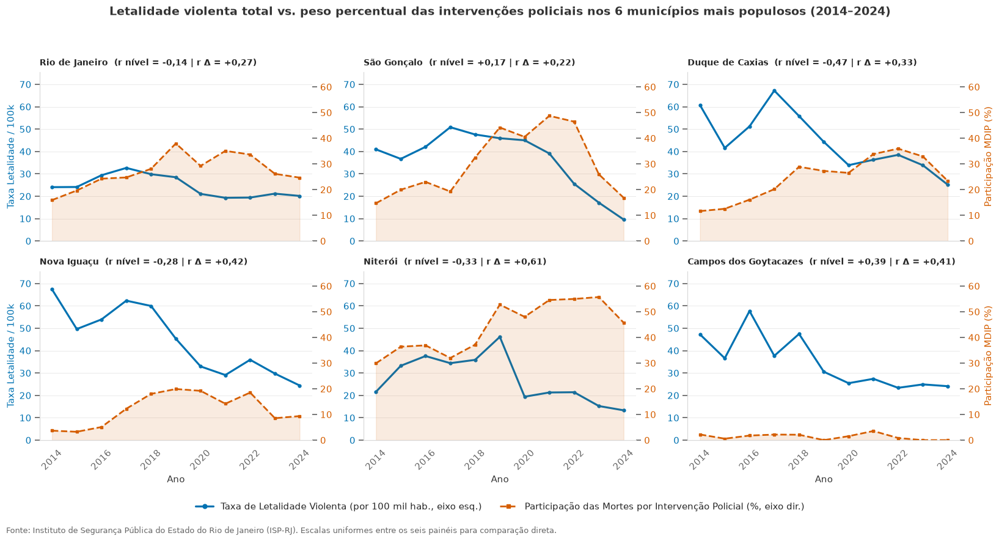

In [21]:
fig, axes = plt.subplots(2, 3, figsize=(16.5, 8.8), sharex=True)
teto_taxa_p6 = float(painel_p6["taxa_letalidade_anual"].max()) * 1.12
teto_prop_p6 = min(100.0, float(painel_p6["prop_mdip_pct"].max()) * 1.18)

for idx_ax, (ax, mun) in enumerate(zip(axes.flat, ordem_mun_p6)):
    sub = painel_p6.loc[painel_p6["nome_municipio"] == mun].sort_values("ano")
    linha_r = resumo_p6.loc[resumo_p6["municipio"] == mun].iloc[0]
    r_val = linha_r["r_nivel"]
    r_diff_val = linha_r["r_variacao_anual"]

    ax.plot(
        sub["ano"], sub["taxa_letalidade_anual"],
        color=PALETA["azul"], lw=2.3, marker="o", ms=3.5, label="Taxa Letalidade Violenta / 100k",
    )
    ax.set_ylim(0, teto_taxa_p6)
    ax.tick_params(axis="y", labelcolor=PALETA["azul"])
    ax.grid(axis="x", visible=False)

    ax_r = ax.twinx()
    ax_r.spines["top"].set_visible(False)
    ax_r.spines["right"].set_color(PALETA["vermelho"])
    ax_r.fill_between(sub["ano"], 0, sub["prop_mdip_pct"], color=PALETA["vermelho"], alpha=0.12)
    ax_r.plot(
        sub["ano"], sub["prop_mdip_pct"],
        color=PALETA["vermelho"], lw=2.0, ls="--", marker="s", ms=3.0, label="Participação MDIP (%)",
    )
    ax_r.set_ylim(0, teto_prop_p6)
    ax_r.tick_params(axis="y", labelcolor=PALETA["vermelho"])
    ax_r.grid(False)
    if idx_ax % 3 == 2:
        ax_r.set_ylabel("Participação MDIP (%)", color=PALETA["vermelho"])

    ax.set_title(f"{mun}  (r nível = {formatar_numero(r_val, 2, sinal=True)} | r Δ = {formatar_numero(r_diff_val, 2, sinal=True)})", loc="left", fontsize=10, pad=8)

for ax in axes[:, 0]:
    ax.set_ylabel("Taxa Letalidade / 100k", color=PALETA["azul"])
for ax in axes[1, :]:
    ax.set_xlabel("Ano")
    ax.tick_params(axis="x", rotation=45)

handles_leg = [
    plt.Line2D([0], [0], color=PALETA["azul"], lw=2.3, marker="o", ms=5, label="Taxa de Letalidade Violenta (por 100 mil hab., eixo esq.)"),
    plt.Line2D([0], [0], color=PALETA["vermelho"], lw=2.0, ls="--", marker="s", ms=4.5, label="Participação das Mortes por Intervenção Policial (%, eixo dir.)"),
]
fig.legend(handles=handles_leg, loc="lower center", ncol=2, bbox_to_anchor=(0.5, 0.03), frameon=False, fontsize=10.5)

fig.suptitle(
    f"Letalidade violenta total vs. peso percentual das intervenções policiais nos 6 municípios mais populosos ({int(painel_p6['ano'].min())}–{int(painel_p6['ano'].max())})",
    fontsize=13.5, fontweight="bold", y=0.985, color=PALETA["cinza_escuro"],
)
fig.text(0.01, 0.005, f"{FONTE_PADRAO} Escalas uniformes entre os seis painéis para comparação direta.", fontsize=9, color=PALETA["cinza_medio"])
plt.tight_layout(rect=[0, 0.075, 1, 0.95])
plt.show()

In [22]:
cores_mun_p6 = [
    PALETA["azul"], PALETA["vermelho"], PALETA["verde"],
    PALETA["laranja"], PALETA["roxo"], PALETA["azul_claro"],
]
mapa_cores_p6 = dict(zip(ordem_mun_p6, cores_mun_p6))

fig_p6 = px.line(
    painel_p6,
    x="ano",
    y="prop_mdip_pct",
    color="nome_municipio",
    category_orders={"nome_municipio": ordem_mun_p6},
    color_discrete_map=mapa_cores_p6,
    markers=True,
    hover_data={
        "taxa_letalidade_anual": ":.1f",
        "mdip": ":,.0f",
        "letalidade": ":,.0f",
        "prop_mdip_pct": ":.1f",
    },
    labels={
        "ano": "Ano",
        "prop_mdip_pct": "Participação de MDIP na Letalidade Violenta (%)",
        "nome_municipio": "Município",
        "taxa_letalidade_anual": "Taxa Letalidade / 100k",
        "mdip": "MDIP (abs.)",
        "letalidade": "Letalidade Total (abs.)",
    },
    title=(
        f"<b>Evolução da Participação (%) das Mortes por Intervenção Policial nos 6 Municípios Mais Populosos ({int(painel_p6['ano'].min())}–{int(painel_p6['ano'].max())})</b>"
        "<br><sup>Proporção de mortes por intervenção de agente do Estado no total anual da letalidade violenta</sup>"
    ),
)

fig_p6.update_traces(line=dict(width=2.3), marker=dict(size=5.5))
fig_p6.update_layout(
    height=500,
    hovermode="x unified",
    legend=dict(orientation="h", yanchor="bottom", y=-0.20, xanchor="center", x=0.5),
    margin=dict(l=50, r=30, t=95, b=105),
    xaxis=dict(dtick=2),
)
adicionar_fonte_plotly(fig_p6, y=-0.27)
fig_p6.show()

### Leitura Analítica

- **Clivagem metrópole–interior na composição da letalidade:** nos municípios metropolitanos, a participação da MDIP atingiu patamares elevados — **Niterói** chegou a **55,70%** em 2023 (45,71% em 2024), **São Gonçalo** a **48,72%** (2021), **Rio de Janeiro** a **37,95%** (2019), **Duque de Caxias** a **35,93%** (2022) e **Nova Iguaçu** a **19,89%** (2019). Em **Campos dos Goytacazes** (Interior), a fatia permaneceu residual (máximo de **3,55%** em 2021; **0,00%** em 2024).
- **Longo prazo vs. oscilações anuais:** entre 2014 e 2024, todos os seis municípios reduziram substancialmente suas taxas gerais (ex.: São Gonçalo de 40,93 para 9,58; Nova Iguaçu de 67,36 para 24,41). Em **nível**, quatro dos seis exibem correlação negativa entre fatia de MDIP e taxa geral (**Duque de Caxias** $r = -0{,}47$; **Niterói** $-0{,}33$; **Nova Iguaçu** $-0{,}28$; **Rio de Janeiro** $-0{,}14$), pois os demais crimes contra a vida recuaram mais depressa que as mortes em confronto. Em **variações anuais ($\Delta$)**, porém, a correlação é positiva nos seis municípios ($+0{,}22$ a $+0{,}61$): anos de aceleração da participação policial tendem a coincidir com repiques pontuais da letalidade total. Como a MDIP compõe o próprio denominador do indicador, o resultado expressa sobretudo mudanças na composição interna da violência letal.

## 9. Vitimização policial e letalidade subsequente: tendência comum ou escalada de curto prazo?

> **Pergunta de domínio 7:** *Existe correlação temporal observável (como picos e vales simultâneos) entre a quantidade de policiais mortos em serviço e a escalada da letalidade violenta geral nos meses subsequentes?*

Encerramos o estudo testando uma hipótese frequente no debate público: se meses com mais policiais mortos em serviço (PM + PC em `df_policial`) são seguidos por escalada generalizada da letalidade estadual (`df_evol_uf`) nos meses $t+1$ a $t+3$. Em séries temporais longas, duas variáveis que compartilham declínio secular exibem correlação elevada em nível mesmo sem resposta dinâmica imediata. Por isso, comparamos a correlação cruzada $\text{Corr}(X_t, Y_{t+k})$ ($k \in \{0, 1, 2, 3\}$) **em nível** e **em primeira diferença mensal** ($\Delta X_t$ vs. $\Delta Y_{t+k}$), contra a banda de referência exploratória aproximada sob hipótese de ruído branco ($\pm 1{,}96/\sqrt{n_{\text{diff}}}$, sem pré-branqueamento formal).

In [23]:
exigir_colunas(
    df_policial,
    ["ano", "mes", "quantidade_policial_militar_morto_servico", "quantidade_policial_civil_morto_servico"],
    "df_policial",
)
exigir_colunas(
    df_evol_uf,
    ["ano", "mes", "quantidade_letalidade_violenta", "quantidade_homicidio_intervencao_policial"],
    "df_evol_uf",
)

pol_mensal = (
    df_policial.groupby(["ano", "mes"], as_index=False)[
        ["quantidade_policial_militar_morto_servico", "quantidade_policial_civil_morto_servico"]
    ]
    .sum()
)
pol_mensal["policiais_mortos_servico"] = (
    pol_mensal["quantidade_policial_militar_morto_servico"]
    + pol_mensal["quantidade_policial_civil_morto_servico"]
)

serie_p7 = (
    pol_mensal.merge(
        df_evol_uf[["ano", "mes", "quantidade_letalidade_violenta", "quantidade_homicidio_intervencao_policial"]],
        on=["ano", "mes"],
        how="inner",
        validate="one_to_one",
    )
    .sort_values(["ano", "mes"])
    .reset_index(drop=True)
)
serie_p7["data"] = pd.to_datetime({"year": serie_p7["ano"], "month": serie_p7["mes"], "day": 1})

serie_p7["mm6_policiais"] = serie_p7["policiais_mortos_servico"].rolling(6, center=True).mean()
serie_p7["mm6_letalidade"] = serie_p7["quantidade_letalidade_violenta"].rolling(6, center=True).mean()

serie_p7["d_policiais"] = serie_p7["policiais_mortos_servico"].diff()
serie_p7["d_letalidade"] = serie_p7["quantidade_letalidade_violenta"].diff()
serie_p7["d_mdip"] = serie_p7["quantidade_homicidio_intervencao_policial"].diff()

lags = [0, 1, 2, 3]
resultados_lag = []
for k in lags:
    r_let_nivel = serie_p7["policiais_mortos_servico"].corr(serie_p7["quantidade_letalidade_violenta"].shift(-k))
    r_let_diff = serie_p7["d_policiais"].corr(serie_p7["d_letalidade"].shift(-k))
    r_mdip_nivel = serie_p7["policiais_mortos_servico"].corr(serie_p7["quantidade_homicidio_intervencao_policial"].shift(-k))
    r_mdip_diff = serie_p7["d_policiais"].corr(serie_p7["d_mdip"].shift(-k))
    n_eff_diff = int(
        pd.concat([serie_p7["d_policiais"], serie_p7["d_letalidade"].shift(-k)], axis=1)
        .dropna()
        .shape[0]
    )
    resultados_lag.append({
        "lag_meses": k,
        "n_efetivo_diff": n_eff_diff,
        "r_letalidade_nivel": r_let_nivel,
        "r_letalidade_diff": r_let_diff,
        "r_mdip_nivel": r_mdip_nivel,
        "r_mdip_diff": r_mdip_diff,
    })

resumo_lags_p7 = pd.DataFrame(resultados_lag).round(4)
n_meses_p7 = len(serie_p7)
n_diff_p7 = int(serie_p7["d_policiais"].notna().sum())
limiar_sig_95 = 1.96 / np.sqrt(n_diff_p7)

In [24]:
fig_p7 = make_subplots(
    rows=2, cols=1, shared_xaxes=True, vertical_spacing=0.08,
    subplot_titles=(
        "Policiais Mortos em Serviço por Mês (PM + PC) e Média Móvel 6 Meses",
        "Letalidade Violenta Estadual por Mês e Média Móvel 6 Meses",
    ),
)

fig_p7.add_trace(
    go.Bar(
        x=serie_p7["data"], y=serie_p7["policiais_mortos_servico"],
        name="Policiais mortos (mês)", marker_color=PALETA["laranja"], opacity=0.45,
    ),
    row=1, col=1,
)
fig_p7.add_trace(
    go.Scatter(
        x=serie_p7["data"], y=serie_p7["mm6_policiais"],
        name="Média móvel 6m (Policiais)", line=dict(color=PALETA["vermelho"], width=2.4),
    ),
    row=1, col=1,
)

fig_p7.add_trace(
    go.Scatter(
        x=serie_p7["data"], y=serie_p7["quantidade_letalidade_violenta"],
        name="Letalidade violenta (mês)", line=dict(color=PALETA["azul_claro"], width=1.2), opacity=0.65,
    ),
    row=2, col=1,
)
fig_p7.add_trace(
    go.Scatter(
        x=serie_p7["data"], y=serie_p7["mm6_letalidade"],
        name="Média móvel 6m (Letalidade)", line=dict(color=PALETA["azul"], width=2.5),
    ),
    row=2, col=1,
)

fig_p7.update_yaxes(title_text="Policiais / mês", row=1, col=1)
fig_p7.update_yaxes(title_text="Vítimas / mês", row=2, col=1)
fig_p7.update_xaxes(title_text="Data", row=2, col=1)
fig_p7.update_layout(
    height=600,
    hovermode="x unified",
    legend=dict(orientation="h", yanchor="bottom", y=-0.16, xanchor="center", x=0.5),
    title=dict(
        text="<b>Série Mensal Comparada: Policiais Mortos em Serviço vs. Letalidade Violenta no RJ</b>",
        x=0.02,
    ),
    margin=dict(l=55, r=30, t=80, b=105),
)
adicionar_fonte_plotly(fig_p7, y=-0.22)
fig_p7.show()

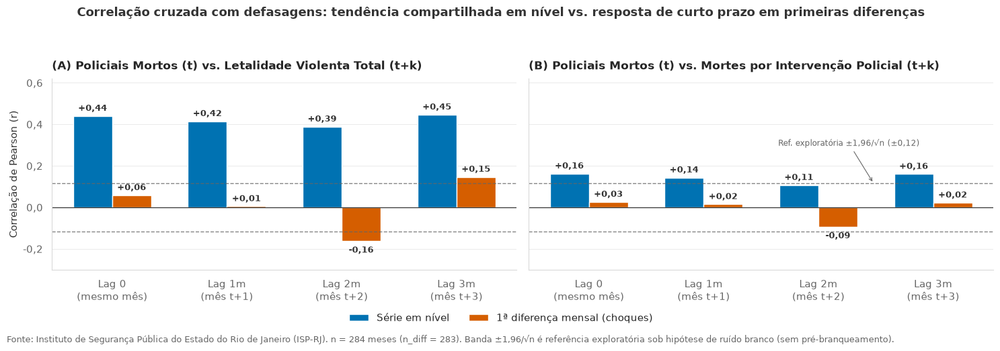

In [25]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.0), sharey=True)
x_pos = np.arange(len(lags))
larg = 0.34
rotulos_lag = [f"Lag {k}m\n(mês t+{k})" if k > 0 else "Lag 0\n(mesmo mês)" for k in lags]

for ax, col_niv, col_dif, titulo in [
    (ax1, "r_letalidade_nivel", "r_letalidade_diff", "(A) Policiais Mortos (t) vs. Letalidade Violenta Total (t+k)"),
    (ax2, "r_mdip_nivel", "r_mdip_diff", "(B) Policiais Mortos (t) vs. Mortes por Intervenção Policial (t+k)"),
]:
    b1 = ax.bar(x_pos - larg / 2, resumo_lags_p7[col_niv], width=larg, color=PALETA["azul"], label="Série em nível")
    b2 = ax.bar(x_pos + larg / 2, resumo_lags_p7[col_dif], width=larg, color=PALETA["vermelho"], label="1ª diferença mensal (choques)")
    ax.axhline(0, color=PALETA["cinza_escuro"], lw=0.9)
    ax.axhline(limiar_sig_95, color=PALETA["cinza_medio"], ls="--", lw=1.0, alpha=0.8)
    ax.axhline(-limiar_sig_95, color=PALETA["cinza_medio"], ls="--", lw=1.0, alpha=0.8)

    for bars in (b1, b2):
        for bar in bars:
            h = bar.get_height()
            offset = 0.015 if h >= 0 else -0.025
            ax.text(
                bar.get_x() + bar.get_width() / 2, h + offset,
                formatar_numero(h, 2, sinal=True), ha="center", va="bottom" if h >= 0 else "top",
                fontsize=9, fontweight="bold", color=PALETA["cinza_escuro"],
            )

    ax.set_title(titulo, loc="left", pad=10)
    ax.set_xticks(x_pos)
    ax.set_xticklabels(rotulos_lag)
    ax.grid(axis="x", visible=False)

ax1.set_ylabel("Correlação de Pearson (r)")
ax1.set_ylim(-0.30, 0.62)
ax1.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: formatar_numero(v, 1)))
ax2.annotate(
    f"Ref. exploratória ±1,96/√n (±{formatar_numero(limiar_sig_95, 2)})",
    xy=(2.48, limiar_sig_95), xytext=(1.65, limiar_sig_95 + 0.18),
    fontsize=8.5, color=PALETA["cinza_medio"],
    arrowprops=dict(arrowstyle="->", color=PALETA["cinza_medio"], lw=0.8),
)

handles_p7, labels_p7 = ax1.get_legend_handles_labels()
fig.legend(handles_p7, labels_p7, loc="lower center", ncol=2, bbox_to_anchor=(0.5, 0.02), frameon=False, fontsize=10.5)

fig.suptitle(
    "Correlação cruzada com defasagens: tendência compartilhada em nível vs. resposta de curto prazo em primeiras diferenças",
    fontsize=13, fontweight="bold", y=0.99, color=PALETA["cinza_escuro"],
)
fig.text(
    0.01, -0.01,
    f"{FONTE_PADRAO} n = {n_meses_p7} meses (n_diff = {n_diff_p7}). Banda ±1,96/√n é referência exploratória sob hipótese de ruído branco (sem pré-branqueamento).",
    fontsize=9, color=PALETA["cinza_medio"],
)
plt.tight_layout(rect=[0, 0.07, 1, 0.94])
plt.show()

### Leitura Analítica

- **Tendência secular compartilhada em nível (2003–2026):** nos **284 meses** integrados (596 policiais mortos em serviço; pico de 10 em outubro de 2004), a correlação em nível com a letalidade estadual mantém-se moderada e quase constante em todas as defasagens (**lag 0: $+0{,}441$**; **lag 1: $+0{,}415$**; **lag 2: $+0{,}389$**; **lag 3: $+0{,}447$**). Essa estabilidade entre lags caracteriza co-movimento de longo prazo — ambas as séries declinaram ao longo de duas décadas —, não uma reação mecânica no mês seguinte.
- **Efeito nulo em primeiras diferenças:** removida a tendência, a correlação imediata desaparece: na letalidade total, **lag 0 = $+0{,}059$** e **lag 1 = $+0{,}005$** (muito abaixo da banda $\pm 0{,}117$); contra MDIP, **todos os quatro lags permanecem dentro da faixa de ruído branco** ($+0{,}026$, $+0{,}015$, $-0{,}093$ e $+0{,}023$). As oscilações de sinais opostos em lag 2 ($-0{,}162$) e lag 3 ($+0{,}147$) na letalidade total — acima da referência exploratória de $\pm 0{,}117$ — apontam reversão à média e autocorrelação/sazonalidade residual após diferenciação (sem pré-branqueamento), não escalada sustentada.
- **Escala de observação:** os dados mensais estaduais não corroboram relação causal direta entre mortes de policiais e escalada agregada nos meses seguintes; eventuais respostas operacionais tendem a ocorrer em escala **microlocal** (CISP/AISP) e janelas de **dias**, diluindo-se na agregação mensal.

## 10. Conclusão

### Síntese Integrada dos Achados

Ao longo das sete perguntas de domínio, a integração das bases oficiais do ISP-RJ revela que a segurança pública fluminense não se resume a uma curva única de queda ou alta. Entre 2003 e 2022, a taxa estadual de letalidade violenta recuou pela metade (54,3 → 25,5/100 mil hab.) e o total de armas apreendidas caiu 44,4% (2007–2024), mas **o perfil e a geografia da violência mudaram estruturalmente**:

1. **Sofisticação bélica e hipótese de atuação policial:** os fuzis mais que triplicaram em volume (+242,1%) e sextuplicaram sua fatia no arsenal (1,93% → 11,90%), acompanhando a substituição de revólveres por pistolas. Sob a hipótese do grupo, uma atuação policial mais combativa ao crime organizado — sobretudo na Capital — pode ter contribuído simultaneamente para a queda da letalidade violenta e para o aumento das apreensões de fuzis.
2. **Redistribuição territorial do crime:** a queda acentuada na Capital (−66,7%) e em Grande Niterói (−52,7%) frente à maior rigidez do Interior (−24,6%) inverteu o ordenamento histórico entre Capital e Interior em 2022, enquanto a Baixada Fluminense manteve o maior risco proporcional.
3. **Fenômenos territorialmente distintos:** a letalidade policial e o armamento pesado formam um corredor metropolitano contínuo (15 das 39 AISPs; $\rho = 0{,}834$), ao passo que o feminicídio concentra suas maiores taxas no Interior e cresceu em 2017–2025 na contramão da letalidade geral.
4. **Regularidade sazonal e cautela causal:** todas as regiões compartilham picos em fevereiro–março e vales em julho–agosto; nos grandes municípios metropolitanos, a fatia de MDIP cresceu mesmo com queda da letalidade total; e a relação entre policiais mortos em serviço e letalidade estadual nos meses seguintes reflete tendência histórica comum, sem evidência de escalada sistemática em primeiras diferenças.

### Recomendações

1. **Focalização do controle de armas pesadas (Seções 6 e 7):** direcionar inteligência policial e rastreamento de rotas de armamento de guerra para as **15 AISPs do Cluster 1** (corredor metropolitano e Angra dos Reis), quebrando o ciclo entre fuzis e letalidade em confronto.
2. **Estratégias específicas contra o feminicídio no Interior (Seção 3):** estruturar redes de prevenção, DEAMs e patrulhas Maria da Penha descoladas da agenda de confronto armado urbano, priorizando os polos do **Interior** com maiores taxas proporcionais.
3. **Planejamento sazonal e reforço no Interior (Seções 4 e 5):** concentrar ações preventivas no **primeiro quadrimestre (janeiro–abril)** — especialmente fevereiro e março — e reduzir a defasagem de queda da letalidade no **Interior** (−24,6% vs. −66,7% na Capital).
4. **Atualização da infraestrutura de dados abertos (Seções 3, 6 e 8):** disponibilizar populações oficiais pós-2022 por CISP/AISP (Censo IBGE 2022), desagregação por sexo e vigências históricas na tabela CISP–AISP–RISP.

### Limitações Metodológicas

1. **Cobertura populacional até 2022:** `PopulacaoEvolucaoMensalCisp` e a população estadual de `df_letalidade` encerram-se em **2022**, limitando taxas por AISP a `2003–2022` (`2017–2022` no feminicídio), exigindo `ffill` nas taxas estaduais de armas de 2023–2024 e motivando a estimativa populacional indireta por registros de ocorrência na P6.
2. **Denominador feminino e pequenas amostras:** na ausência de população por sexo por AISP, adotou-se a proporção fixa de 50% de mulheres no cálculo das taxas de feminicídio; ademais, AISPs menos populosas apresentam contagens baixas, aumentando a sensibilidade das taxas proporcionais.
3. **Natureza administrativa dos registros:** todos os indicadores derivam de Registros de Ocorrência (ROs), sujeitos a mudanças legais (Lei nº 13.104/2015), subnotificação e intensidade operacional, exigindo leitura estritamente descritiva e exploratória.

### Referências

- **Instituto de Segurança Pública do Estado do Rio de Janeiro (ISP-RJ).** Portal de Dados Abertos (*ISPDados*). Disponível em: [https://www.ispdados.rj.gov.br](https://www.ispdados.rj.gov.br).
- **ISP-RJ.** *Relação RISP × AISP × CISP*. Disponível em: [https://www.ispdados.rj.gov.br/Arquivos/Relacao_RISPxAISPxCISP.pdf](https://www.ispdados.rj.gov.br/Arquivos/Relacao_RISPxAISPxCISP.pdf).
- **ISP-RJ.** *Configuração histórica da AISP 1 na Capital (2010)* e **SEPM/PMERJ**, *Reativação do 1º BPM em São Gonçalo (2025)*. Disponível em: [https://www.rj.gov.br/isp/sites/default/files/2022-05/BalaPerdidaJanSet2010.pdf](https://www.rj.gov.br/isp/sites/default/files/2022-05/BalaPerdidaJanSet2010.pdf) e [https://sepm.rj.gov.br/unidade/?id=159](https://sepm.rj.gov.br/unidade/?id=159).
- **Brasil.** Lei nº 13.104, de 9 de março de 2015 (Lei do Feminicídio).